# Lịch sử Lab03 — Study full fine-tuning 10 epoch

**Đây là thí nghiệm lịch sử.** Kết quả chính sau vòng giảm overfitting nằm trong [notebook tích hợp](lab03_huggingface_complete.ipynb), dùng frozen trial epoch 9. Giữ study này để đối chiếu; không gán metric của các protocol khác nhau cho cùng một model.


Đây là notebook trình bày **kết quả đã chạy thật**, không phải template training. Chạy **Run All** ở `MODE="view"` để đọc artifacts offline, không tải model/dataset, không cần GPU. Training nằm trong [04_kaggle_10epoch_study.ipynb](04_kaggle_10epoch_study.ipynb).

Study: `20261026T184219Z_study_94f2ba7b`, nguồn code `ca58b27`. Đã kiểm tra 128 file của review ZIP khớp SHA256 và toàn bộ hash source khớp phiên chạy. Cả ba candidate hoàn tất 10 epoch; checkpoint winner là **LR=3e-5, step 1700, epoch ≈3,184**, threshold validation **0,5**. Test đúng **889/1.066**, Accuracy **83,3959%**, Macro-F1 **83,3952%**.

**Kết luận cần giữ đúng:** study hơn baseline TF-IDF nhưng không hơn kết quả lịch sử 3 epoch trên cùng test. Không chọn lại candidate hay threshold theo test. Hoàn thành 10 epoch không có nghĩa lấy weights epoch 10.

## Roadmap phase và module tham chiếu

| Phase | Câu hỏi | Module / file | Evidence và visualize |
|---|---|---|---|
| P0 | Có đúng code và đúng dữ liệu đã chạy không? | [study_evidence.py](../src/study_evidence.py), [runs.py](../src/utils/runs.py) | SHA256, fingerprints, source revision |
| P1 | Pretrained sentiment vận hành thế nào? | [classifier.py](../src/models/classifier.py), [analysis.py](../src/analysis.py) | token heatmap, probabilities, pipeline/manual |
| P2 | Dữ liệu có cân bằng, trùng nội dung hay bị cắt không? | [loader.py](../src/datasets/loader.py), [study.py](../src/study.py) | class counts, token histogram, overlap audit |
| P3 | Baseline học thật đạt mức nào? | [study.py](../src/study.py): fit_text_baseline | C validation table, TF-IDF test comparison |
| P4 | Model học thế nào trong 10 epoch? | [trainer.py](../src/training/trainer.py), [plots.py](../src/utils/plots.py) | 3 epoch curves + 3 step dashboards |
| P5 | Checkpoint nào thắng và vì sao? | [study.py](../src/study.py): choose_candidate | candidate table, Macro-F1/loss trajectories |
| P6 | Threshold có cần khác 0,5 không? | [thresholds.py](../src/training/thresholds.py) | validation sweep và frozen policy |
| P7 | Chất lượng trên test và từng lớp? | [workflow.py](../src/workflow.py), [study_evidence.py](../src/study_evidence.py) | metrics, confusion matrices, per-class table |
| P8 | Ranking, confidence và bất định? | [study.py](../src/study.py): prediction_diagnostics | ROC/PR, reliability, bootstrap CI |
| P9 | Có tốt hơn run cũ không? | [study_review.py](../src/study_review.py) | paired test comparison, overfitting diagnostics |
| P10 | Mô hình sai ở đâu, inference dùng policy gì? | [study.py](../src/study.py), [decision.py](../src/decision.py) | error samples, inference table và PNG |
| P11 | Lấy artifact viết report ra sao? | [publish_artifacts.py](../scripts/publish_artifacts.py) | outputs/published/, tables.json, review_summary.json |

Tham chiếu [description](../description_lab_03.md), [walkthrough](../walkthrough_lab_03.md), [DL training](../../../docs/dl_training.md). Các ảnh hiển thị chính là PNG đã lưu dưới `outputs/`; bảng có records nguồn, không dựng lại bằng suy đoán.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

MODE = "view"
LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
assert LAB is not None, "Hãy mở notebook bên trong repository Lab-DL."
sys.path.insert(0, str(LAB.parents[1]))
from labs.lab03.src.evidence import selected_run, read_json
from labs.lab03.src.study_evidence import audit_study
from labs.lab03.src.study_review import ensure_study_review
from labs.lab03.src.epoch_presentation import ensure_epoch_presentation
SHOW_STEP_DIAGNOSTICS = False

study_run = selected_run("study", root=LAB)
study_audit = audit_study(study_run, root=LAB)
study_review = ensure_study_review(study_run, root=LAB)
epoch_presentation = ensure_epoch_presentation(study_run, root=LAB)
study_tables = read_json(study_review / "tables.json")
study_summary = read_json(study_review / "review_summary.json")
print("Study:", study_run.name, "Audit:", study_audit["status"])
print("Không train, không tải weights, không chọn lại threshold.")

def show_study_image(path, caption):
    path = Path(path)
    assert path.is_file(), f"Thiếu artifact: {path}"
    display(Markdown(caption))
    display(Image(filename=str(path)))

Study: 20261026T184219Z_study_94f2ba7b Audit: passed
Không train, không tải weights, không chọn lại threshold.


## P1 — Exercise 1: tokenizer, pipeline và manual forward

Mô hình SST-2 pretrained chỉ phục vụ Exercise 1. Exercise 2 dùng DistilBERT base với classification head mới, không lấy model đã fine-tune SST-2 để giả thành huấn luyện từ base. Pipeline và manual softmax được đối chiếu trên cùng input/model; không có học weights ở phase này.

,text,label,score,probabilities
0,I love this wonderful movie!,POSITIVE,0.999878,"[0.0001224386360263452, 0.9998775720596313]"
1,This movie was terrible and boring.,NEGATIVE,0.999768,"[0.9997683167457581, 0.00023167315521277487]"
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749,"[0.9967492818832397, 0.0032507420983165503]"


**Exercise 1 — pipeline_manual_comparison.png**

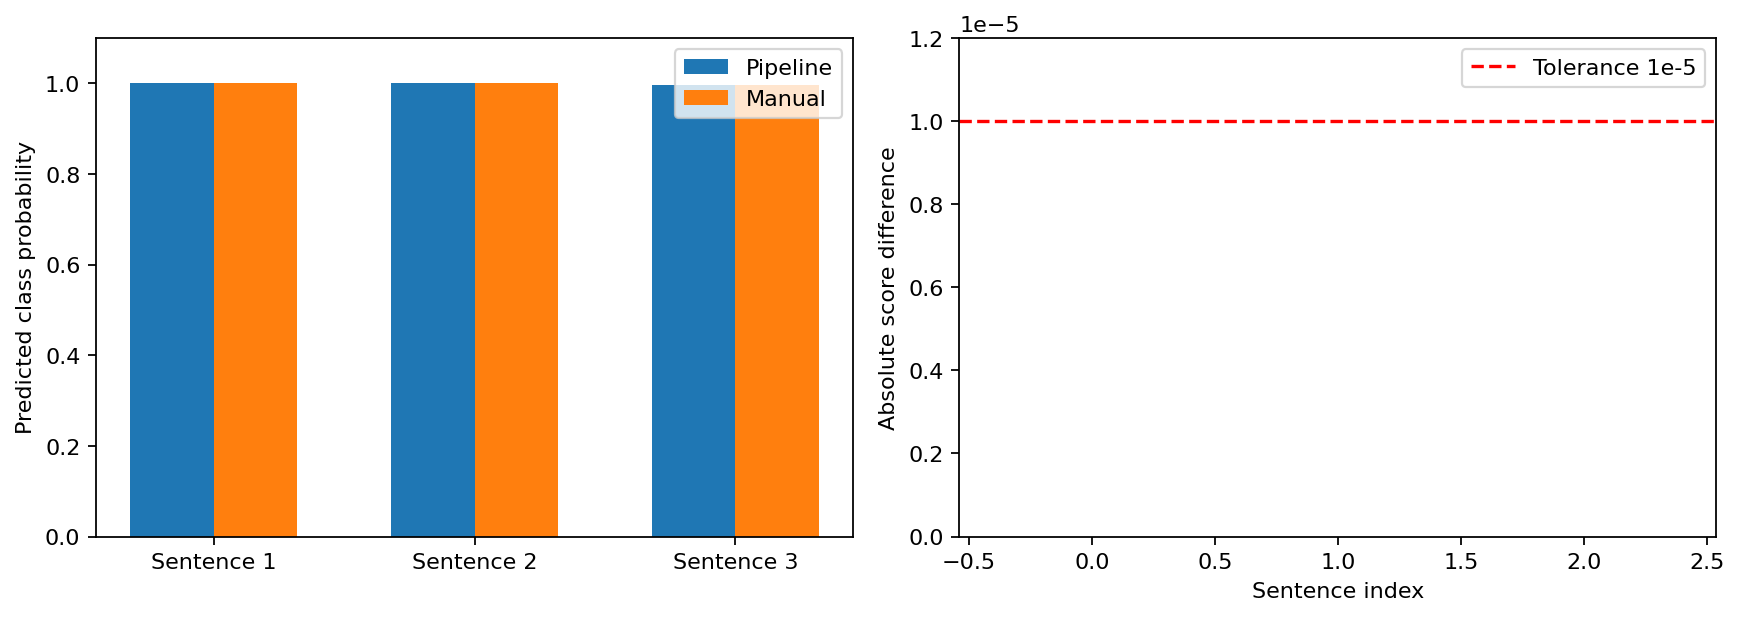

**Exercise 1 — sentiment_predictions.png**

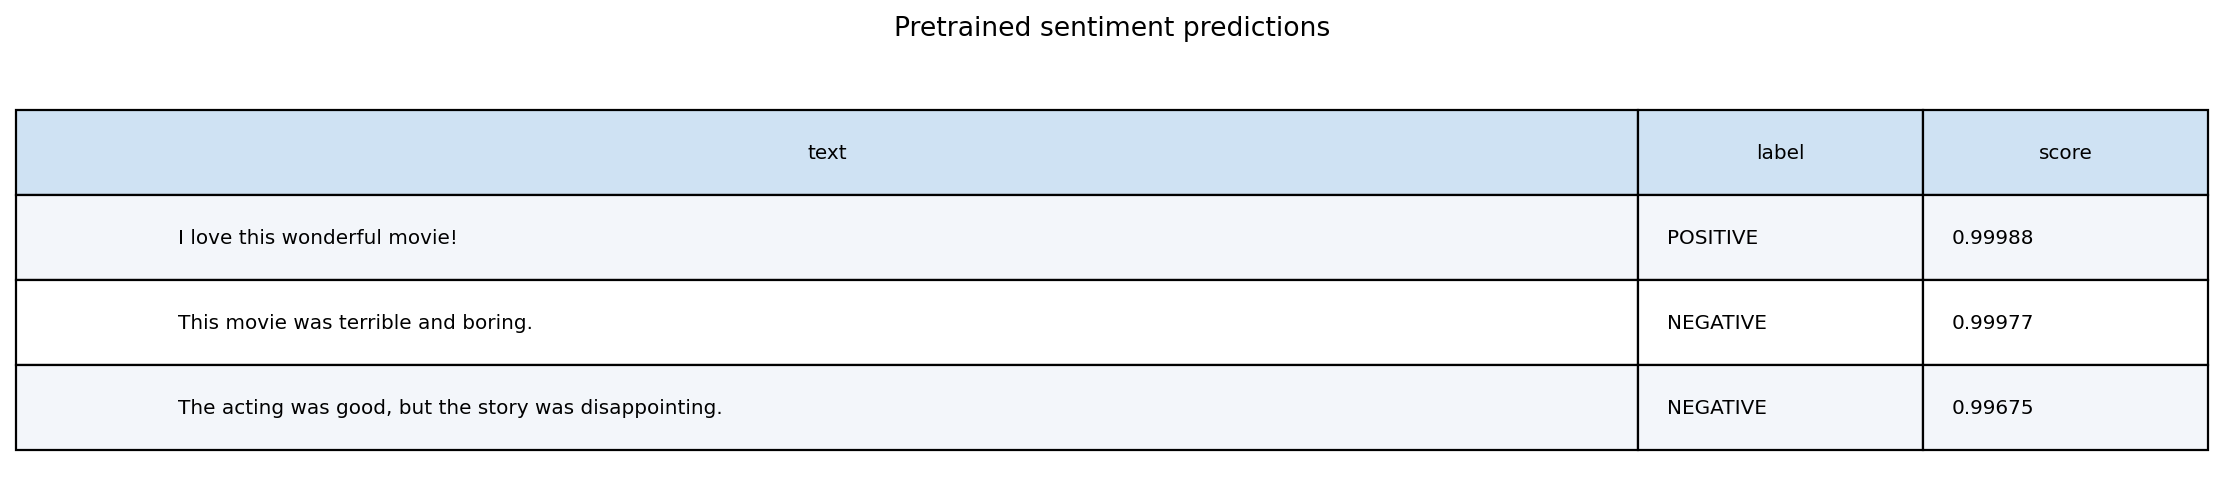

**Exercise 1 — tokenizer_table.png**

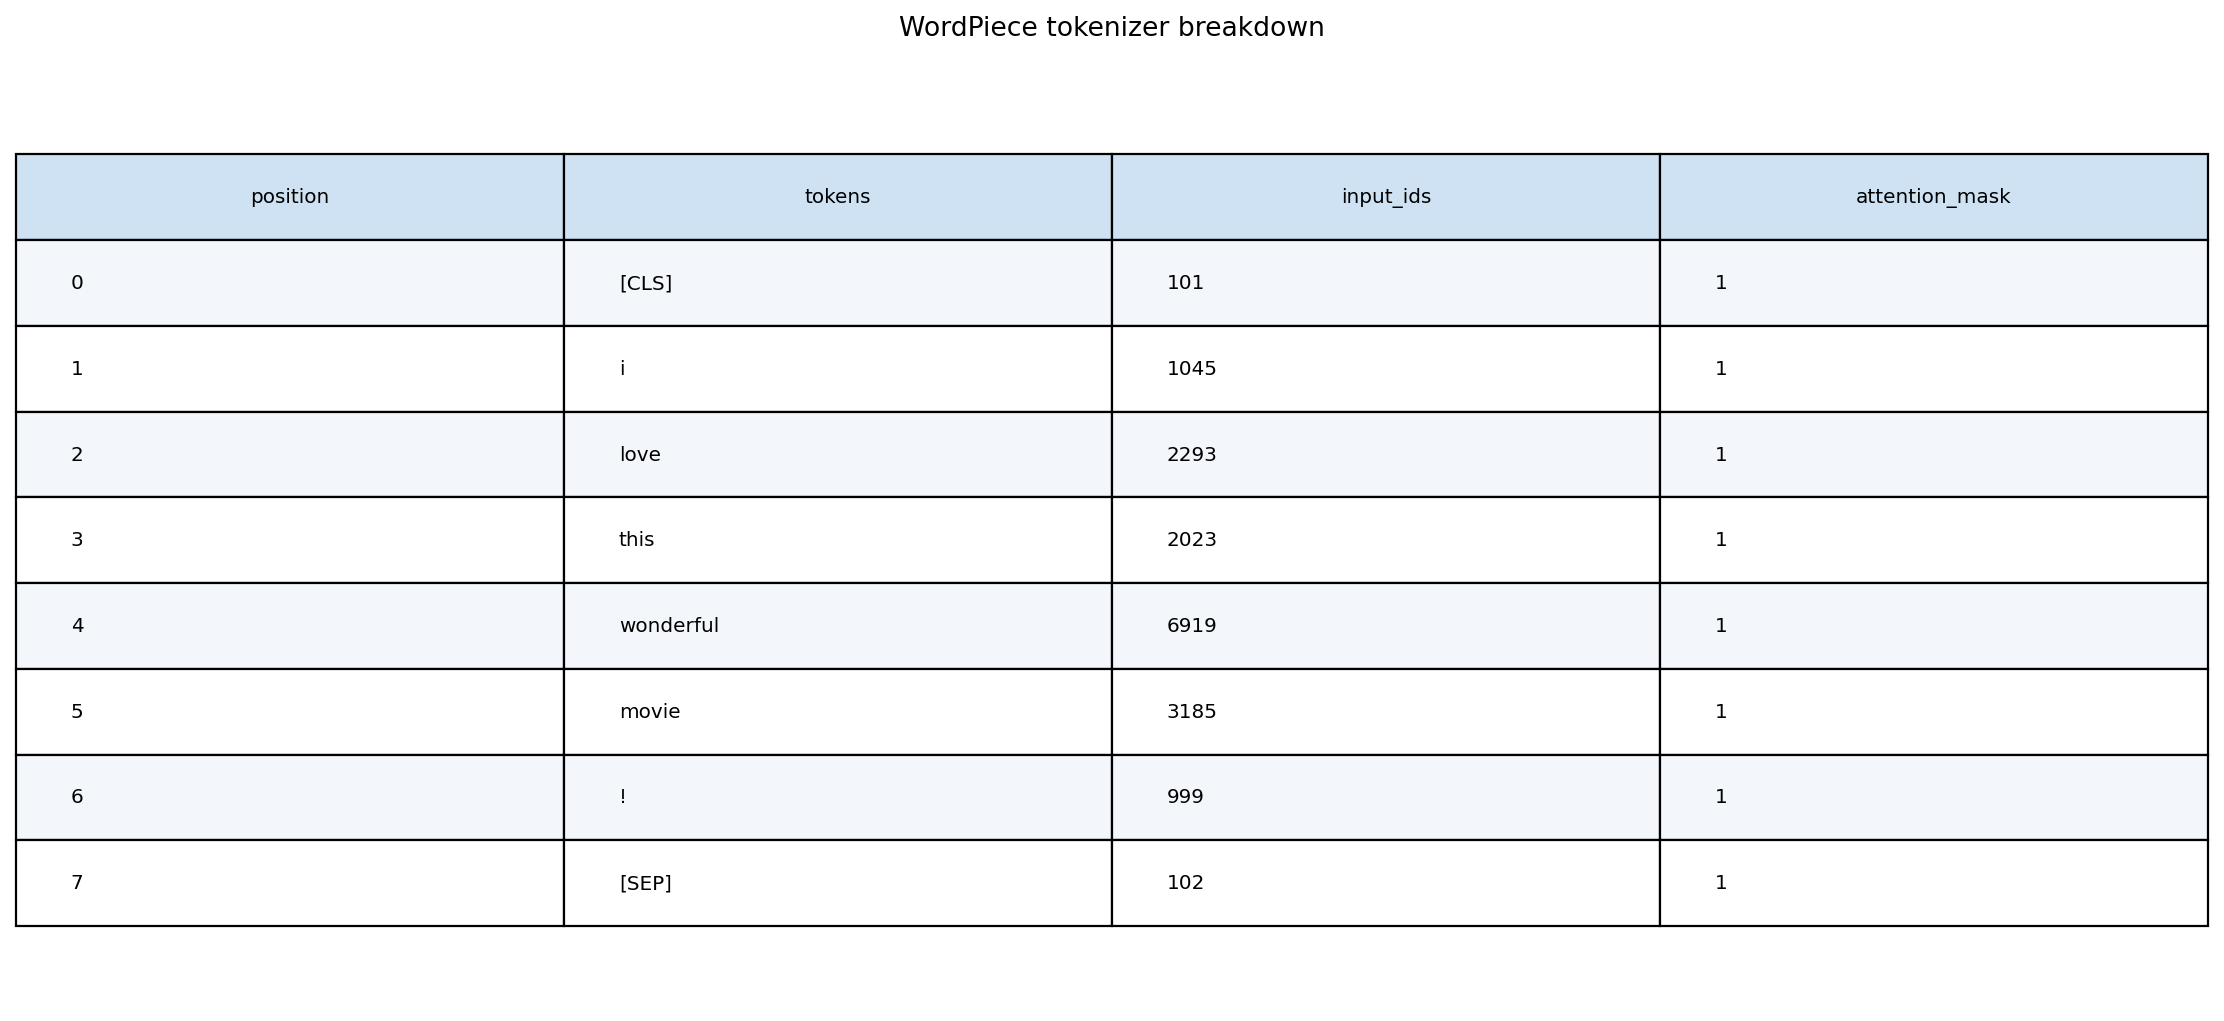

In [2]:
study_exercise1 = LAB / "outputs/runs/20261026T184202Z_exercise1_de76a80c"
study_exercise1_analysis = LAB / "outputs/runs/20261026T184207Z_exercise1_analysis_5406bc6c"
display(pd.DataFrame(read_json(study_exercise1 / "predictions.json")["manual"]))
for path in sorted(study_exercise1_analysis.glob("*.png")):
    show_study_image(path, f"**Exercise 1 — {path.name}**")

## P2 — Full official splits và kiểm toán nội dung

Dữ liệu gồm **8.530 train / 1.066 validation / 1.066 test**; train có 4.265 mẫu mỗi lớp, validation/test có 533 mẫu mỗi lớp. Max length 128; token dài nhất trong train là 78 nên không có train review bị truncation ở cutoff này. Không suy ra test cũng không bị cắt chỉ từ thống kê train.

Audit exact và casefold-whitespace ghi **0 duplicate nội bộ và 0 overlap giữa mọi cặp split**. Đây là hai phép kiểm cụ thể, không chứng minh không có paraphrase, near duplicate hoặc contamination từ pretraining.

,split,samples
0,train,8530
1,validation,1066
2,test,1066


{'mean': 27.368347010550995, 'max': 78, 'truncated_fraction': 0.0}

{'exact': {'within_split_duplicates': {'train': 0, 'validation': 0, 'test': 0},
  'cross_split_overlaps': {'train__validation': 0,
   'train__test': 0,
   'validation__test': 0}},
 'casefold_whitespace': {'within_split_duplicates': {'train': 0,
   'validation': 0,
   'test': 0},
  'cross_split_overlaps': {'train__validation': 0,
   'train__test': 0,
   'validation__test': 0}}}

**Full official class counts**

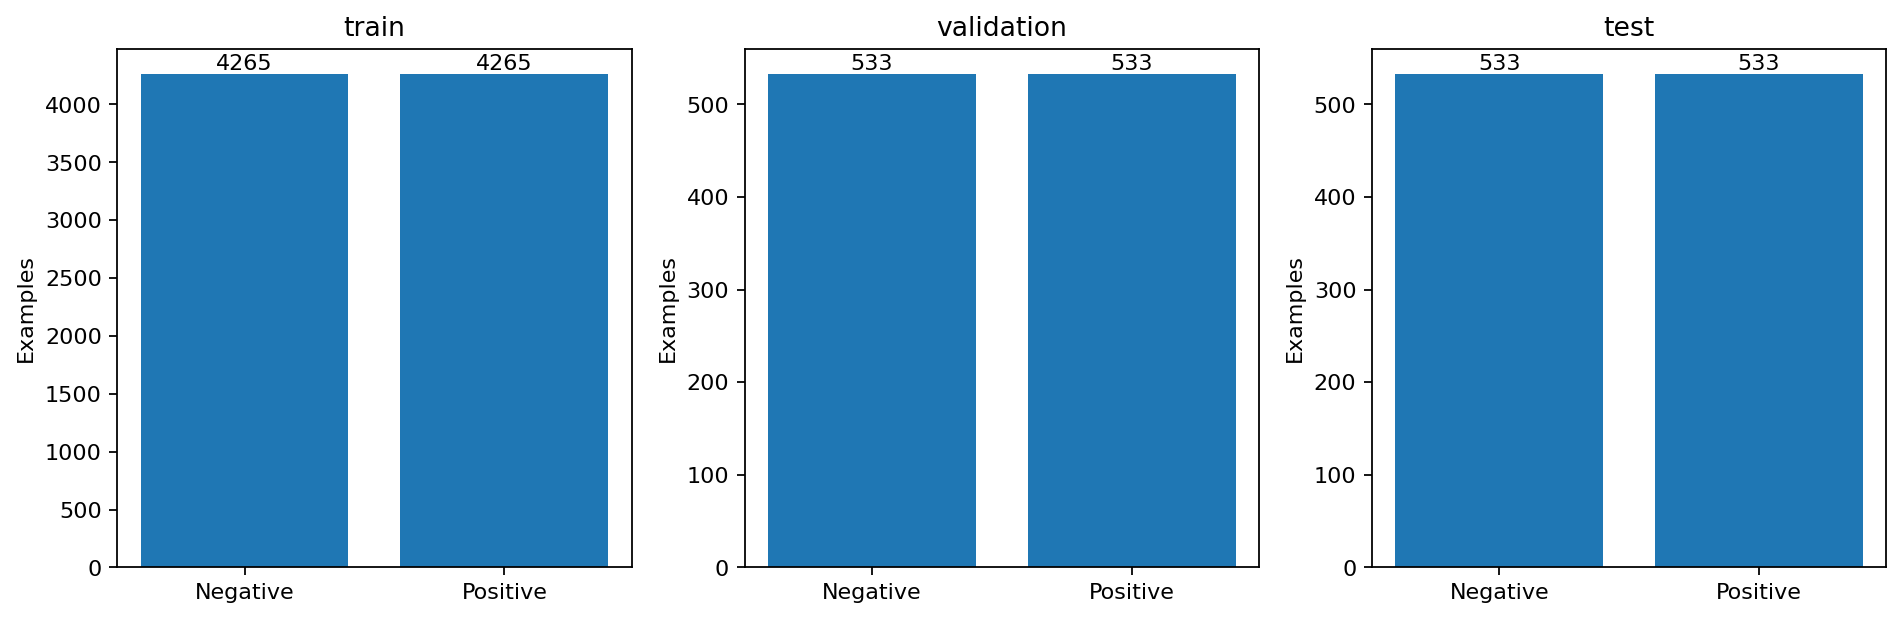

**Độ dài train trước truncation; cutoff=128**

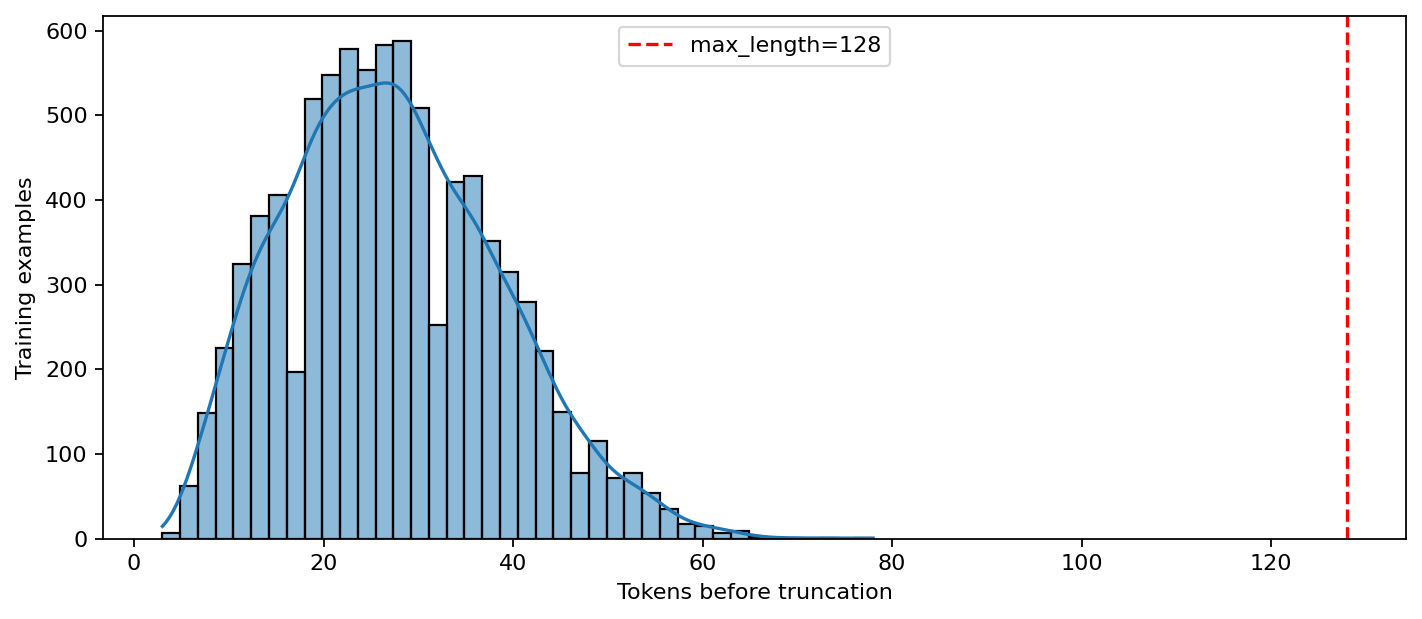

In [3]:
study_winner = LAB / "outputs/runs" / study_summary["winner"]["run_id"]
study_stats = read_json(study_winner / "data_statistics.json")
display(pd.DataFrame([{"split":k,"samples":v} for k,v in study_stats["split_sizes"].items()]))
display(study_stats["train_token_lengths"])
display(read_json(study_run / "split_overlap_audit.json"))
show_study_image(study_run / "class_distribution.png", "**Full official class counts**")
show_study_image(study_winner / "token_length_distribution.png", "**Độ dài train trước truncation; cutoff=128**")

## P3 — Baseline TF-IDF + Logistic Regression

Vocabulary/IDF chỉ fit train; word unigram/bigram, sublinear TF, min_df=2, tối đa 50.000 features. C grid `[0.1, 1, 10]` chọn trên validation Macro-F1, không dựa test. **C=10** thắng với validation Macro-F1 ≈0,748561. Không refit train+validation sau selection để giữ validation cho threshold.

Baseline đạt test Accuracy **78,2364%** ở 0,5 và **78,7054%** với threshold validation 0,4. Threshold 0,4 tăng recall Positive nhưng tăng FP và giảm precision. Đừng bỏ baseline hoặc operating point kém hơn khỏi báo cáo.

,C,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1,loss,selection_split
0,0.1,0.722326,0.713514,0.742964,0.727941,0.722706,0.722326,0.722208,0.645547,validation
1,1.0,0.748593,0.740472,0.765478,0.752768,0.748877,0.748593,0.748521,0.536022,validation
2,10.0,0.748593,0.743119,0.759850,0.751391,0.748719,0.748593,0.748561,0.488585,validation


,model,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,TF-IDF + logistic regression (0.5),0.5,0.782364,0.786667,0.774859,0.789869,0.210131,0.780718,0.782352,421,112,120,413,533,533,1066
1,TF-IDF + validation threshold,0.4,0.787054,0.754153,0.851782,0.722326,0.277674,0.800000,0.786158,385,148,79,454,533,533,1066
2,DistilBERT (0.5),0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066
3,DistilBERT + validation threshold,0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066


**Test comparison của các policy đã chốt trên validation**

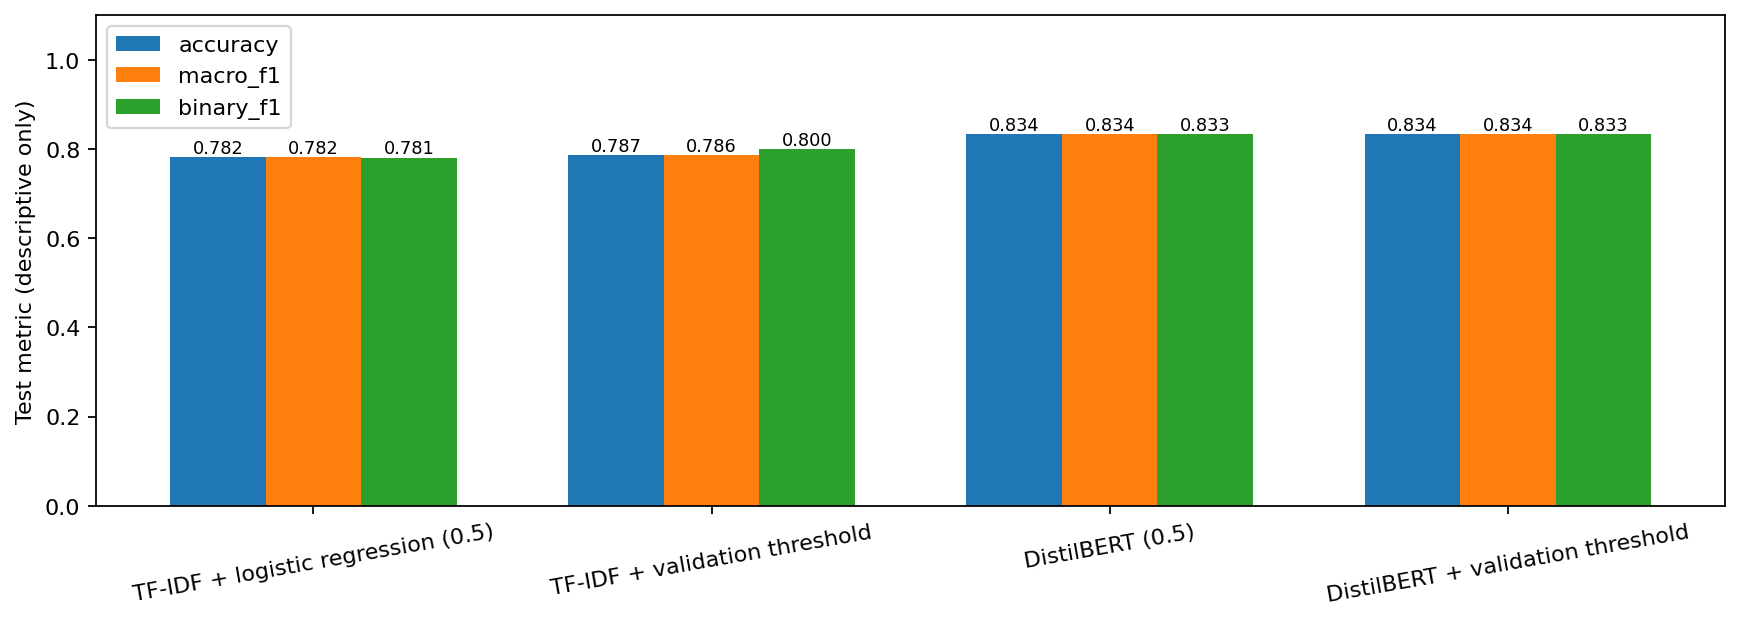

In [4]:
study_baseline_rows = read_json(study_run / "baseline_validation_candidates.json")
display(pd.DataFrame([{k:v for k,v in r.items() if not isinstance(v,list)} for r in study_baseline_rows]))
display(pd.DataFrame(read_json(study_run / "test_comparison.json")))
show_study_image(study_run / "baseline_model_comparison.png", "**Test comparison của các policy đã chốt trên validation**")

## P4 — Học đủ 10 epoch, quan sát theo step

Mỗi candidate có **5.340 Trainer global steps**, 63 mốc validation và 10 lần train-eval cuối epoch. AMP bỏ qua 5/4/5 optimizer updates ở ba LR; số updates thành công là 5.335/5.336/5.335. Không gọi global steps là tất cả đều đã cập nhật weights thành công.

Loss hình epoch đo train và validation ở chế độ eval, dropout tắt. Optimization loss hình step là trung bình cửa sổ trong lúc weights đang đổi, không cùng measurement context. Đường dọc đánh dấu checkpoint được chọn; các mốc sau vẫn chạy đến đủ epoch 10.

**Cách hiển thị đã chỉnh:** biểu đồ chính lấy đúng mốc cuối các epoch 1–10, mỗi đường 10 điểm. Đây là vẽ lại từ history gốc, không train lại, không sửa weights và không làm biến mất overfitting. Dashboard theo step mặc định ẩn (`SHOW_STEP_DIAGNOSTICS=False`).

,run_id,learning_rate,selection_split,macro_f1,loss,completed_epochs,best_step,best_epoch,lowest_validation_loss,lowest_loss_epoch,lowest_loss_macro_f1,final_train_accuracy,final_train_eval_loss,final_validation_macro_f1,final_validation_loss,global_steps,successful_optimizer_updates,amp_skipped_optimizer_steps,validation_milestones,train_runtime_seconds
0,20261026T184223Z_candidate_4b1da858,0.00001,validation,0.849906,0.755625,10.0,3200,5.992509,0.354226,1.685393,0.838603,0.997069,0.017905,0.843339,0.915719,5340,5335,5,63,461.3409
1,20261026T185017Z_candidate_202c0434,0.00002,validation,0.848920,0.747378,10.0,2100,3.932584,0.371871,1.872659,0.836519,0.999883,0.000844,0.843328,1.168640,5340,5336,4,63,457.4038
2,20261026T185804Z_candidate_8308037d,0.00003,validation,0.856473,0.702748,10.0,1700,3.183521,0.368855,1.000000,0.834882,1.000000,0.000044,0.842388,1.241744,5340,5335,5,63,454.3989


### LR=1e-05: best step 3200, epoch 5.993

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T184223Z_candidate_4b1da858,0.00001,1.0,534,0.361184,0.846424,0.409649,0.815197,0.813718
1,20261026T184223Z_candidate_4b1da858,0.00001,2.0,1068,0.196510,0.931067,0.364261,0.843340,0.843316
2,20261026T184223Z_candidate_4b1da858,0.00001,3.0,1602,0.116793,0.962954,0.407902,0.836773,0.836726
3,20261026T184223Z_candidate_4b1da858,0.00001,4.0,2136,0.070221,0.981243,0.523578,0.842402,0.842374
4,20261026T184223Z_candidate_4b1da858,0.00001,5.0,2670,0.044462,0.988746,0.682248,0.840525,0.840516
5,20261026T184223Z_candidate_4b1da858,0.00001,6.0,3204,0.030209,0.993904,0.762776,0.848030,0.847987
6,20261026T184223Z_candidate_4b1da858,0.00001,7.0,3738,0.023675,0.995662,0.810585,0.839587,0.839536
7,20261026T184223Z_candidate_4b1da858,0.00001,8.0,4272,0.020152,0.996600,0.886487,0.843340,0.843316
8,20261026T184223Z_candidate_4b1da858,0.00001,9.0,4806,0.018848,0.996952,0.922118,0.839587,0.839570
9,20261026T184223Z_candidate_4b1da858,0.00001,10.0,5340,0.017905,0.997069,0.915719,0.843340,0.843339


**Đúng 10 điểm cuối epoch: train-eval và validation**

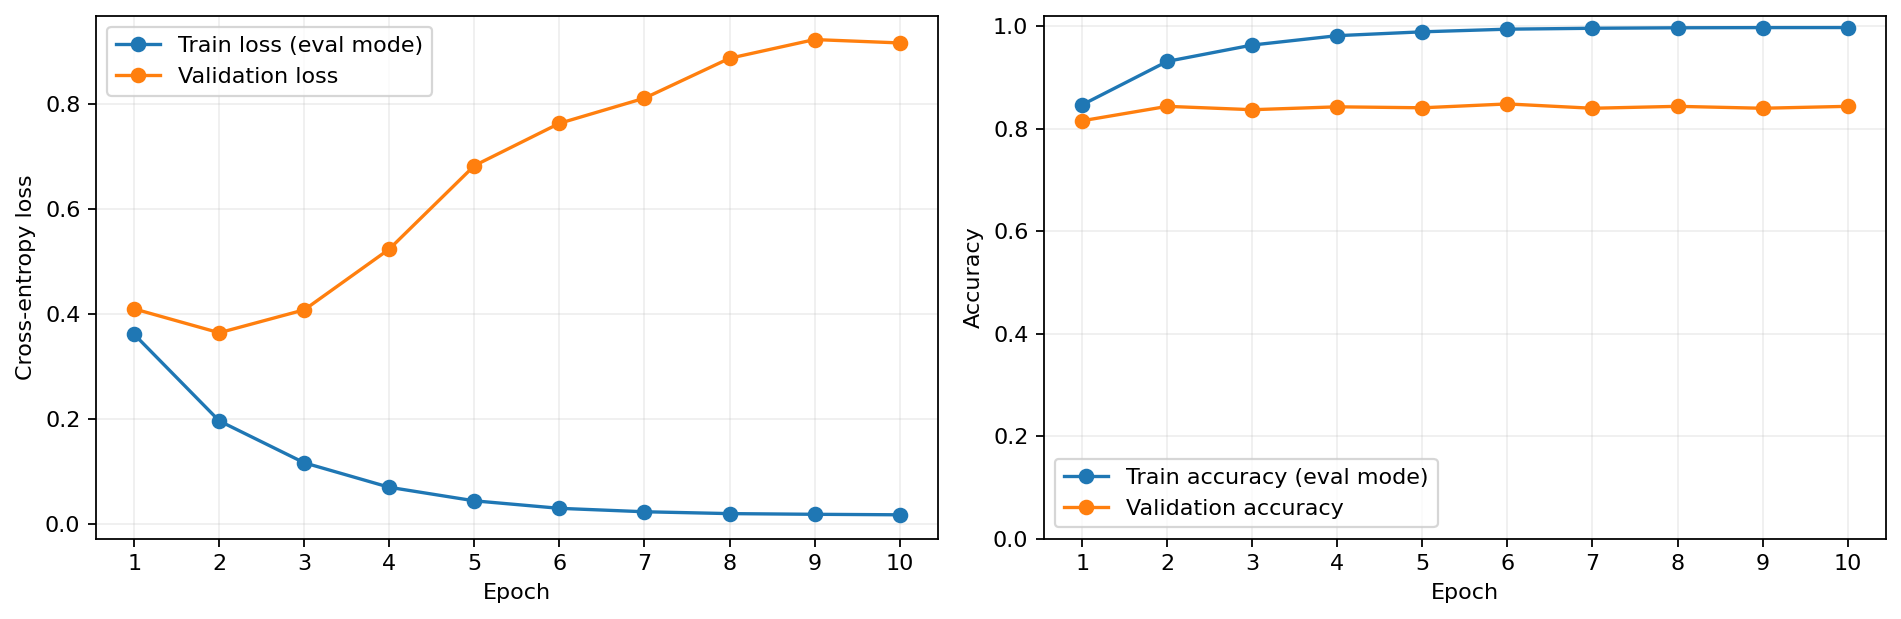

### LR=2e-05: best step 2100, epoch 3.933

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T185017Z_candidate_202c0434,0.00002,1.0,534,0.284754,0.890856,0.375641,0.833959,0.833662
1,20261026T185017Z_candidate_202c0434,0.00002,2.0,1068,0.139032,0.951817,0.401150,0.839587,0.839484
2,20261026T185017Z_candidate_202c0434,0.00002,3.0,1602,0.055867,0.982415,0.515694,0.839587,0.839586
3,20261026T185017Z_candidate_202c0434,0.00002,4.0,2136,0.027041,0.993318,0.798238,0.836773,0.836703
4,20261026T185017Z_candidate_202c0434,0.00002,5.0,2670,0.013019,0.996835,0.858950,0.834897,0.834860
5,20261026T185017Z_candidate_202c0434,0.00002,6.0,3204,0.005685,0.998945,1.010918,0.838649,0.838603
6,20261026T185017Z_candidate_202c0434,0.00002,7.0,3738,0.001735,0.999766,1.061436,0.842402,0.842322
7,20261026T185017Z_candidate_202c0434,0.00002,8.0,4272,0.001151,0.999766,1.119127,0.840525,0.840520
8,20261026T185017Z_candidate_202c0434,0.00002,9.0,4806,0.000924,0.999883,1.158766,0.835835,0.835823
9,20261026T185017Z_candidate_202c0434,0.00002,10.0,5340,0.000844,0.999883,1.168640,0.843340,0.843328


**Đúng 10 điểm cuối epoch: train-eval và validation**

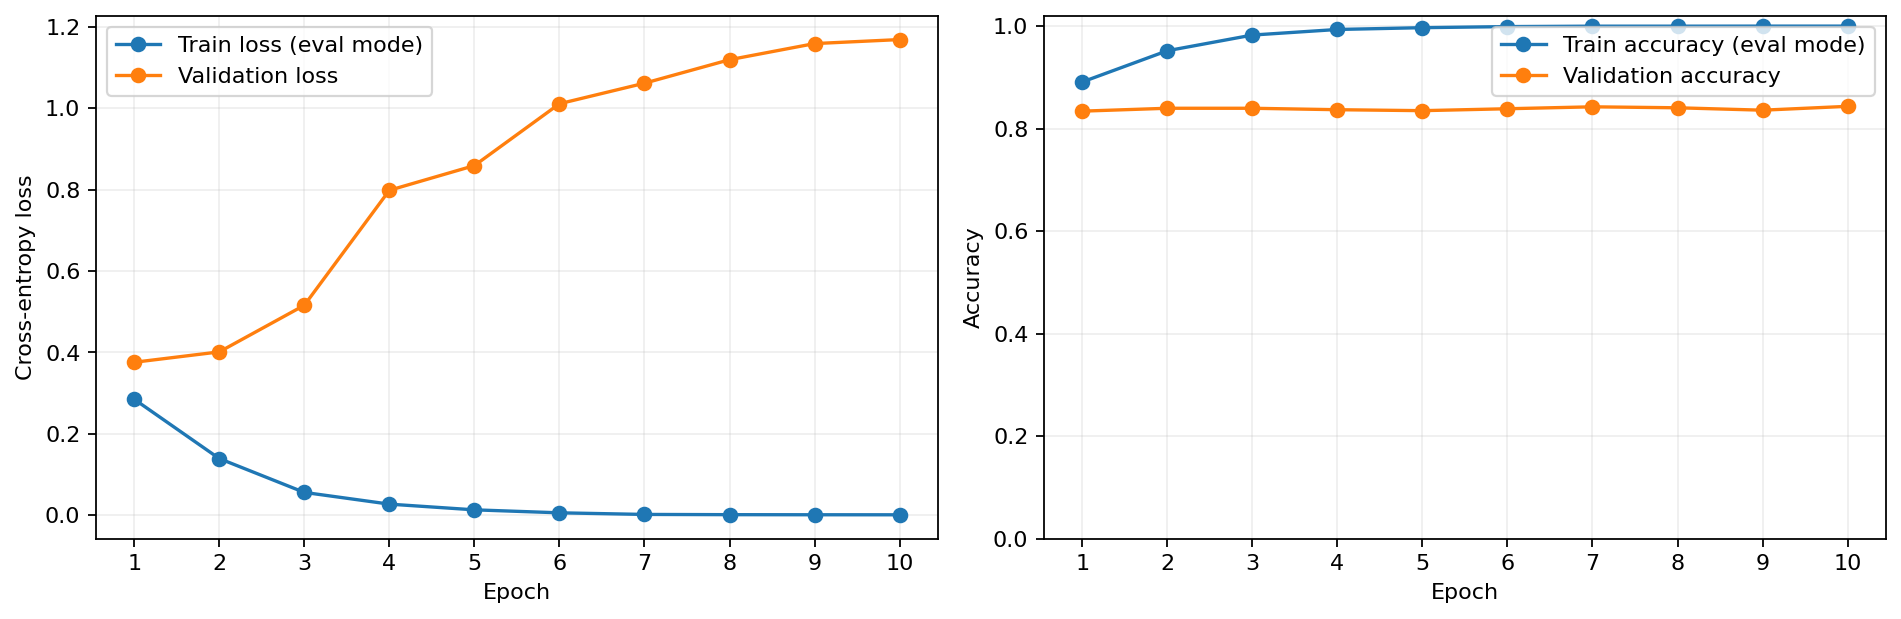

### LR=3e-05: best step 1700, epoch 3.184

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T185804Z_candidate_8308037d,0.00003,1.0,534,0.252050,0.903048,0.368855,0.834897,0.834882
1,20261026T185804Z_candidate_8308037d,0.00003,2.0,1068,0.112389,0.962134,0.401104,0.843340,0.843339
2,20261026T185804Z_candidate_8308037d,0.00003,3.0,1602,0.049154,0.983118,0.538902,0.837711,0.836988
3,20261026T185804Z_candidate_8308037d,0.00003,4.0,2136,0.018800,0.995311,0.802981,0.839587,0.839248
4,20261026T185804Z_candidate_8308037d,0.00003,5.0,2670,0.005281,0.999179,0.958392,0.833959,0.833906
5,20261026T185804Z_candidate_8308037d,0.00003,6.0,3204,0.002950,0.999414,1.118980,0.836773,0.836690
6,20261026T185804Z_candidate_8308037d,0.00003,7.0,3738,0.001412,0.999648,1.150906,0.839587,0.839468
7,20261026T185804Z_candidate_8308037d,0.00003,8.0,4272,0.000568,0.999883,1.208887,0.841463,0.841457
8,20261026T185804Z_candidate_8308037d,0.00003,9.0,4806,0.000055,1.000000,1.204243,0.846154,0.846153
9,20261026T185804Z_candidate_8308037d,0.00003,10.0,5340,0.000044,1.000000,1.241744,0.842402,0.842388


**Đúng 10 điểm cuối epoch: train-eval và validation**

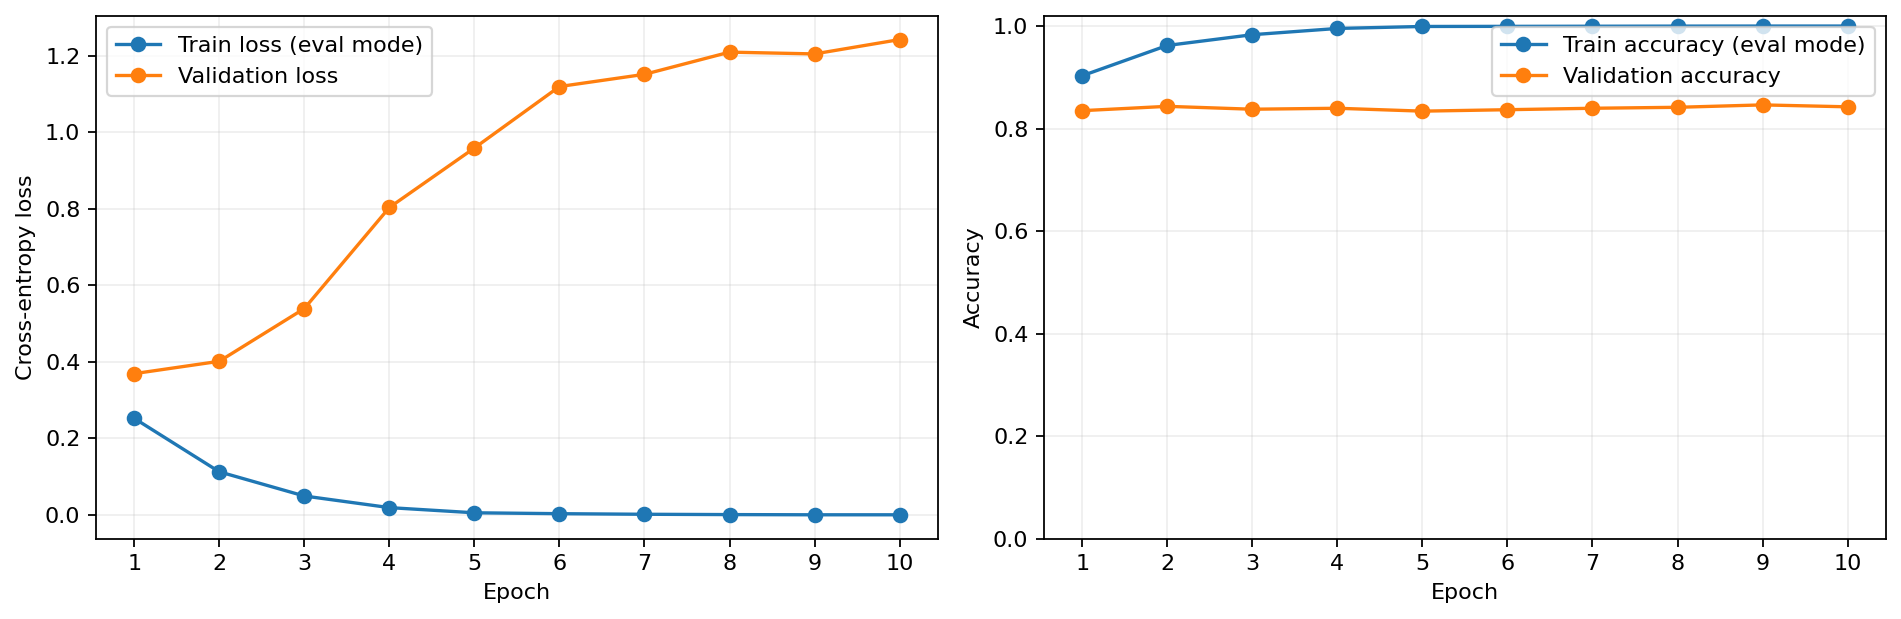

In [5]:
display(pd.DataFrame(study_tables["candidates"]))
for candidate in study_tables["candidates"]:
    source = LAB / "outputs/runs" / candidate["run_id"]
    display(Markdown(f"### LR={candidate['learning_rate']:g}: best step {candidate['best_step']}, epoch {candidate['best_epoch']:.3f}"))
    display(pd.DataFrame([r for r in study_tables["epochs"] if r["run_id"] == candidate["run_id"]]))
    show_study_image(epoch_presentation / candidate["run_id"] / "learning_curves.png", "**Đúng 10 điểm cuối epoch: train-eval và validation**")
    if SHOW_STEP_DIAGNOSTICS:
        show_study_image(source / "step_learning_curves.png", "**Dashboard bổ sung theo step**")

## P5 — Checkpoint winner và dấu hiệu overfitting

LR `3e-5` thắng bằng validation Macro-F1 **85,6473%**, tại **step 1700 / epoch 3,184**, validation loss **0,702748**. Loss thấp nhất của candidate này là **0,368855 tại epoch 1**, nhưng criterion đã chốt là Macro-F1, không phải loss. Không đổi criterion sau khi đã thấy test.

Tại epoch 10, winner đạt **100% train accuracy**, train-eval loss ≈0,0000441, còn validation Macro-F1 ≈84,2388% và loss ≈1,241744. Đây là dấu hiệu học thuộc train và confidence xấu đi trên validation. 100% train accuracy không phải bằng chứng đạt 100% trên dữ liệu mới. Bộ raw/normalized overlap không phát hiện giao nhau, nhưng chưa kiểm tra near-duplicate hoặc pretraining contamination.

**Ba learning rate trên cùng validation**

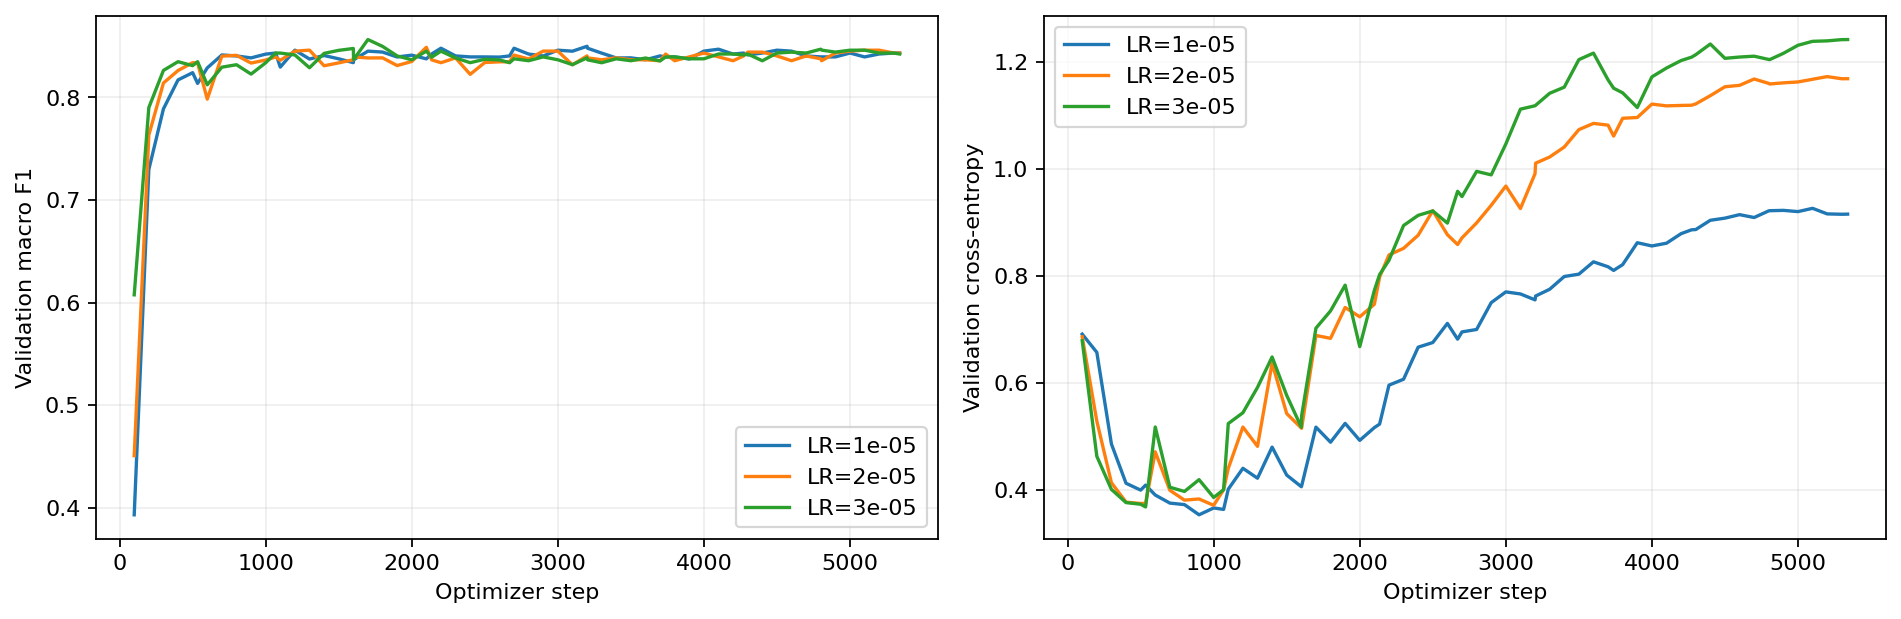

**Best checkpoint khác weights epoch cuối**

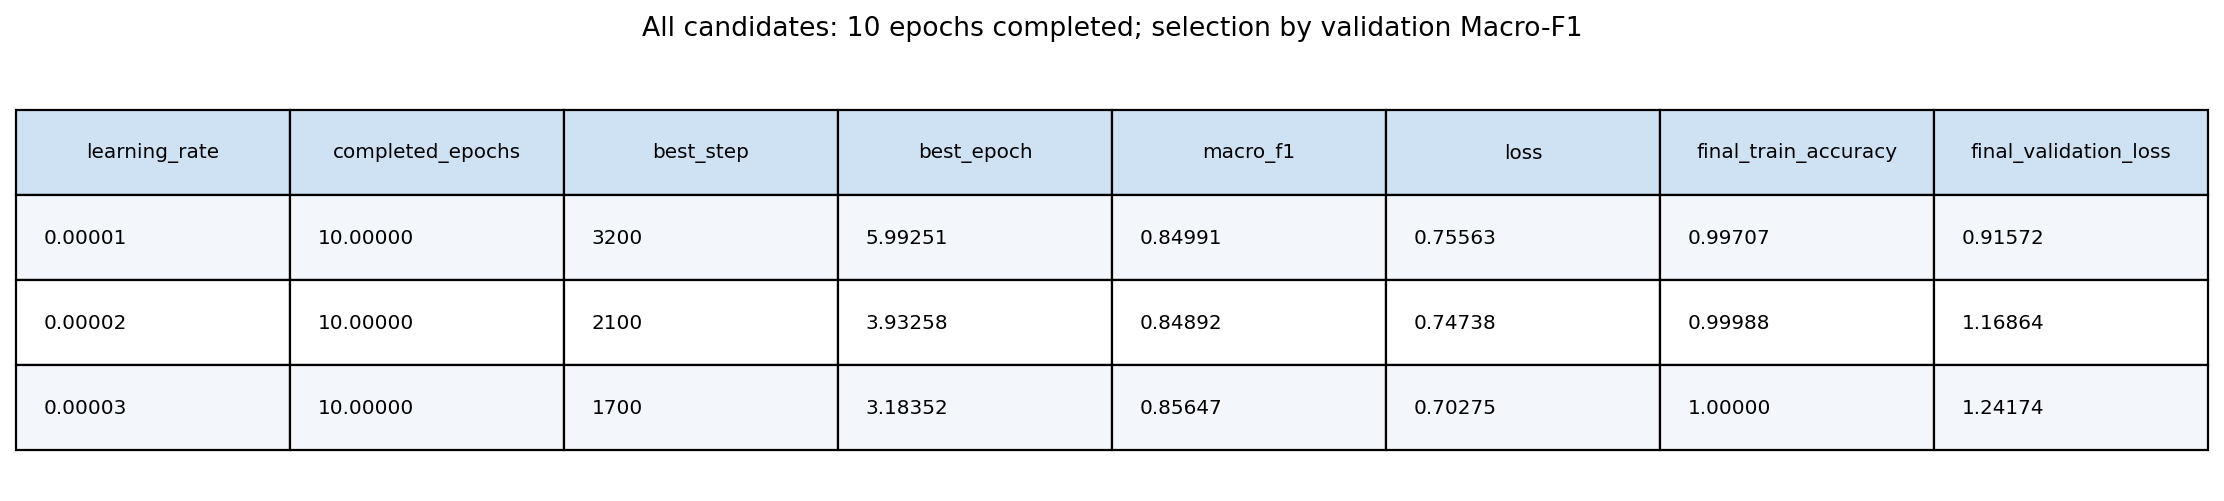

**Generalization gap và validation loss qua đủ 10 epoch**

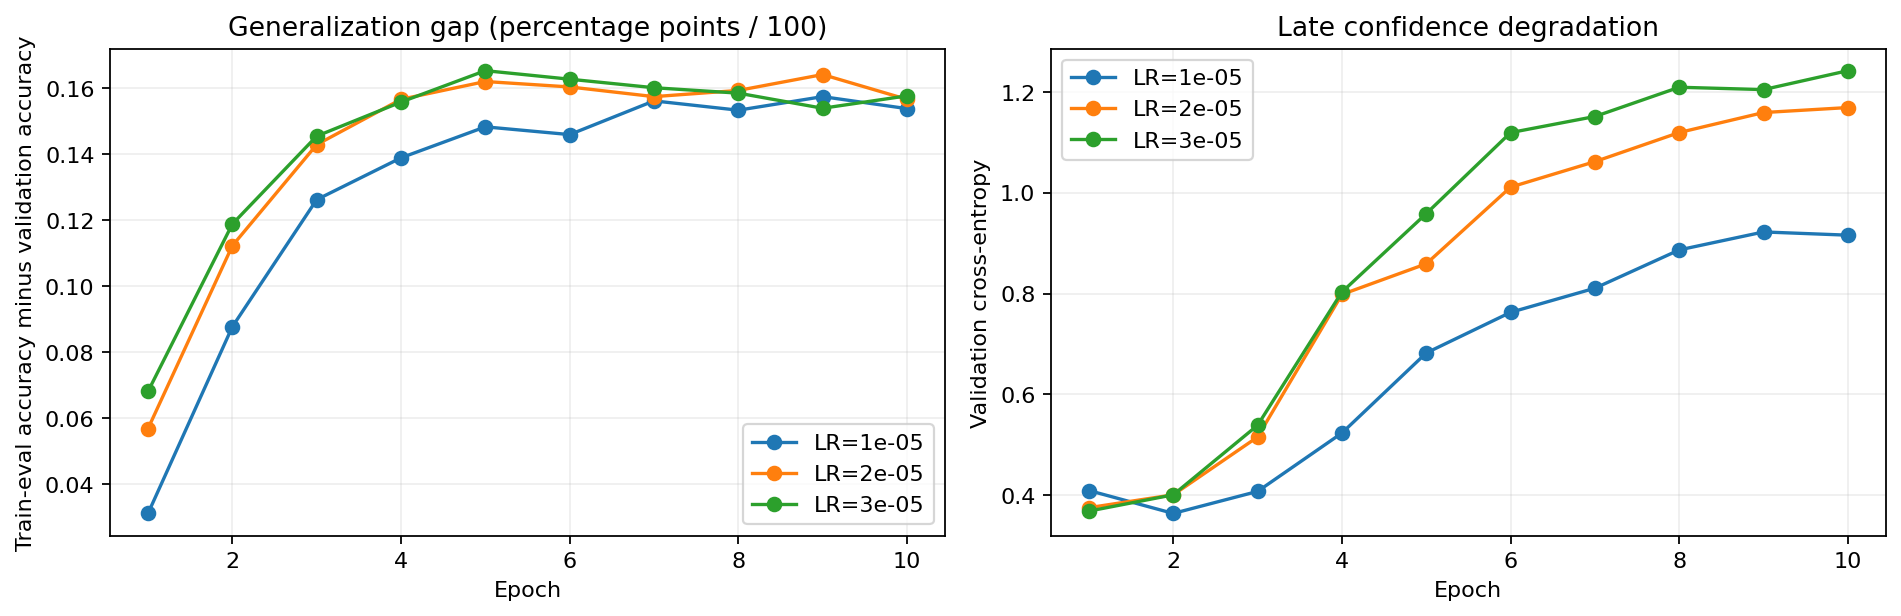

{'winner': {'run_id': '20261026T185804Z_candidate_8308037d',
  'learning_rate': 3e-05,
  'selection_split': 'validation',
  'macro_f1': 0.8564726691922859,
  'loss': 0.7027483582496643,
  'completed_epochs': 10.0,
  'best_step': 1700},
 'threshold': 0.5,
 'selection_split': 'validation',
 'test_used_for_selection': False,
 'candidate_manifest_sha256': '20b5707b2b344f8386f1e929460fd6824da7794ef575bb32ce6a94d093fff705',
 'prior_test_exposure': 'The historical 3-epoch test report was already inspected; this is not a new untouched benchmark.'}

In [6]:
show_study_image(study_run / "candidate_validation_comparison.png", "**Ba learning rate trên cùng validation**")
show_study_image(study_review / "candidate_summary.png", "**Best checkpoint khác weights epoch cuối**")
show_study_image(study_review / "overfitting_diagnostics.png", "**Generalization gap và validation loss qua đủ 10 epoch**")
display(read_json(study_run / "frozen_selection.json"))

## P6 — Threshold validation vẫn có thể là 0,5

Grid đã quét đủ **19 điểm 0,05…0,95**, objective validation Macro-F1; tie-break gần 0,5 rồi nhỏ hơn. Winner chọn **0,5**. Quét threshold không bắt buộc phải tìm ra một threshold khác 0,5 và không bảo đảm nâng test score.

Policy giữ checkpoint SHA256 và validation fingerprint. Review ZIP không có weights nên kiểm toán tại đây xác minh policy liên kết với hash trong manifest, không giả vờ đã chạy lại model. Candidate LR=1e-5 chọn threshold 0,6 nhưng không được đánh giá test để chọn lại winner.

,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.05,0.846154,0.824253,0.879925,0.812383,0.187617,0.851180,0.845978,433,100,64,469,533,533,1066
1,0.10,0.849906,0.832442,0.876173,0.823640,0.176360,0.853748,0.849803,439,94,66,467,533,533,1066
2,0.15,0.846154,0.832432,0.866792,0.825516,0.174484,0.849265,0.846088,440,93,71,462,533,533,1066
3,0.20,0.850844,0.840000,0.866792,0.834897,0.165103,0.853186,0.850806,445,88,71,462,533,533,1066
4,0.25,0.850844,0.841241,0.864916,0.836773,0.163227,0.852914,0.850815,446,87,72,461,533,533,1066
5,0.30,0.849906,0.842202,0.861163,0.838649,0.161351,0.851577,0.849887,447,86,74,459,533,533,1066
6,0.35,0.851782,0.846580,0.859287,0.844278,0.155722,0.852886,0.851774,450,83,75,458,533,533,1066
7,0.40,0.853659,0.849722,0.859287,0.848030,0.151970,0.854478,0.853654,452,81,75,458,533,533,1066
8,0.45,0.854597,0.852612,0.857411,0.851782,0.148218,0.855005,0.854595,454,79,76,457,533,533,1066
9,0.50,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066


,policy,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.5,0.5,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066
1,selected,0.5,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066


**Validation threshold scan của winner**

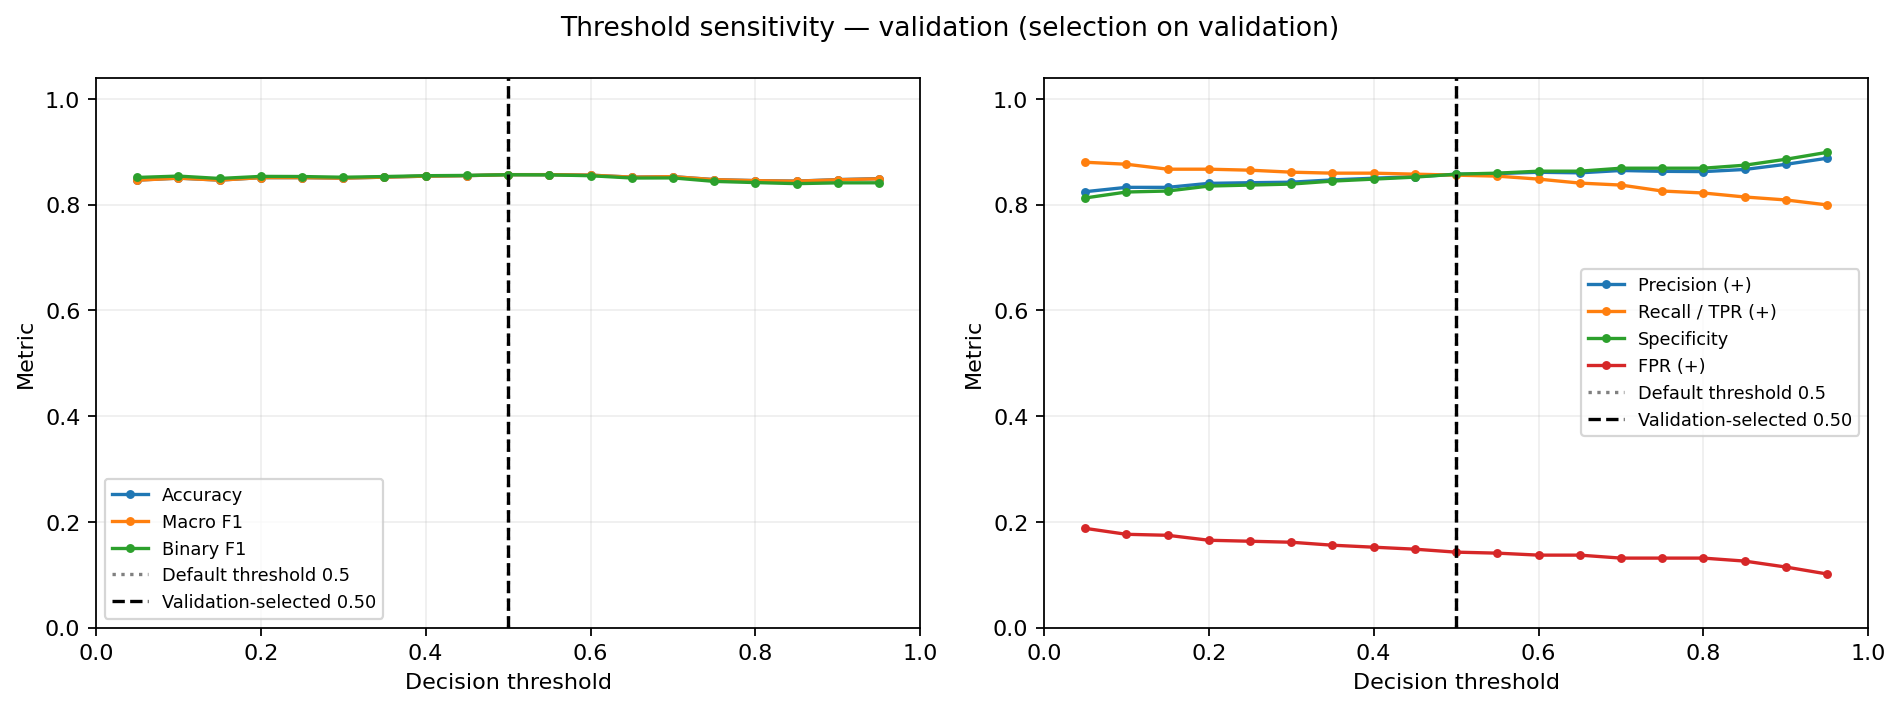

In [7]:
study_policy = read_json(study_run / "decision_threshold.json")
display(pd.DataFrame(study_policy["curve"]))
display(pd.DataFrame([{"policy":"0.5",**study_policy["baseline_metrics"]},
                      {"policy":"selected",**study_policy["selected_metrics"]}]))
show_study_image(study_winner / "validation_threshold/threshold_curves.png", "**Validation threshold scan của winner**")

## P7 — Full test sau khi khóa lựa chọn

Winner đúng **889/1.066**. Confusion matrix: **TN=448, FP=85, FN=92, TP=441**. Accuracy **83,3959%**, Macro-F1 **83,3952%**, Positive Precision **83,8403%**, Recall **82,7392%**, Binary-F1 **83,2861%**.

Test loss đo bằng Trainer **0,7980755568**; NLL dựng lại từ saved probabilities **0,7980772048** là số dẫn xuất riêng, có sai số do float. Threshold chỉ đổi label, không đổi cross-entropy của cùng probabilities. Với threshold 0,5, argmax và policy trùng nhau trong run này.

,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,0.833959,0.838403,0.827392,0.832861,0.834016,0.833959,0.833952


,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count,selection_split,selection_performed_on_test
0,0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066,validation,False


,label,precision,recall,f1-score,support
0,NEGATIVE,0.829630,0.840525,0.835042,533.0
1,POSITIVE,0.838403,0.827392,0.832861,533.0


**Test confusion matrix — argmax**

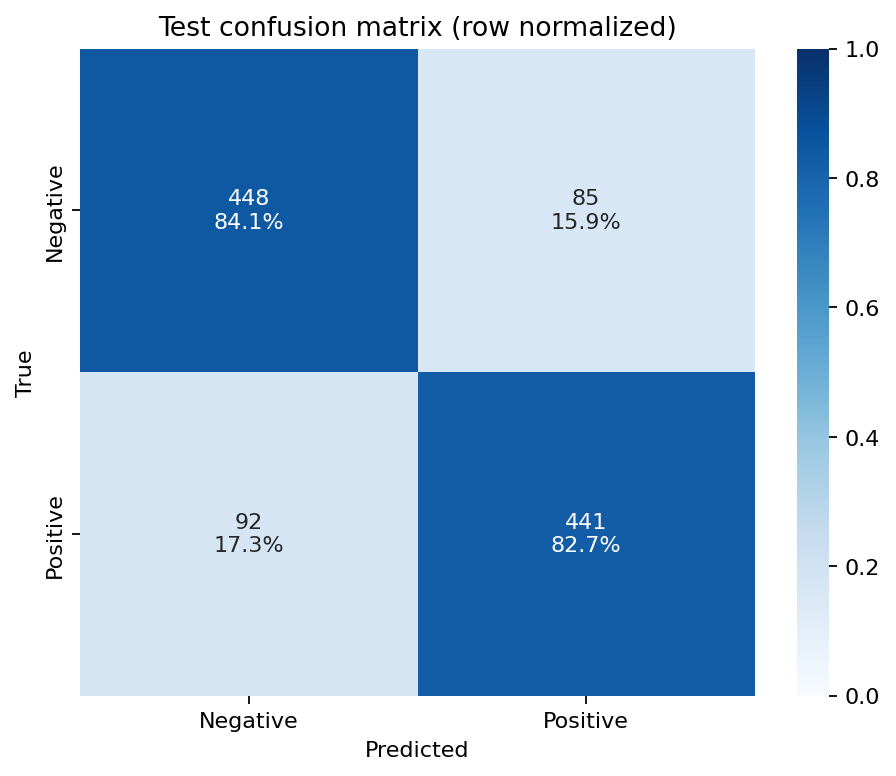

**Test confusion matrix — frozen validation threshold 0.5**

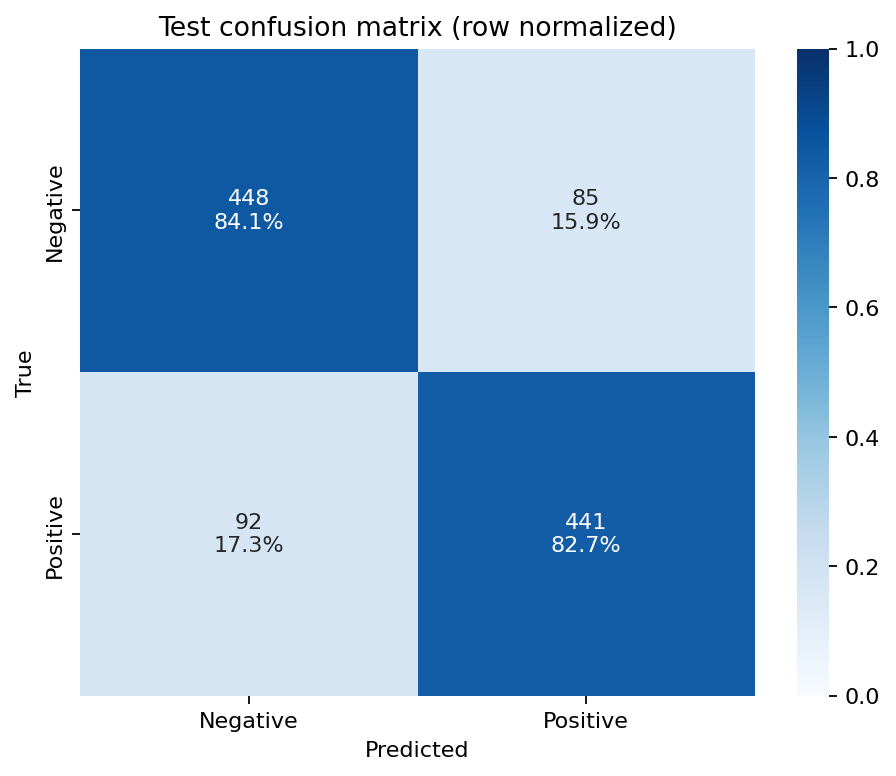

**Metric từng lớp, support=533 mỗi lớp**

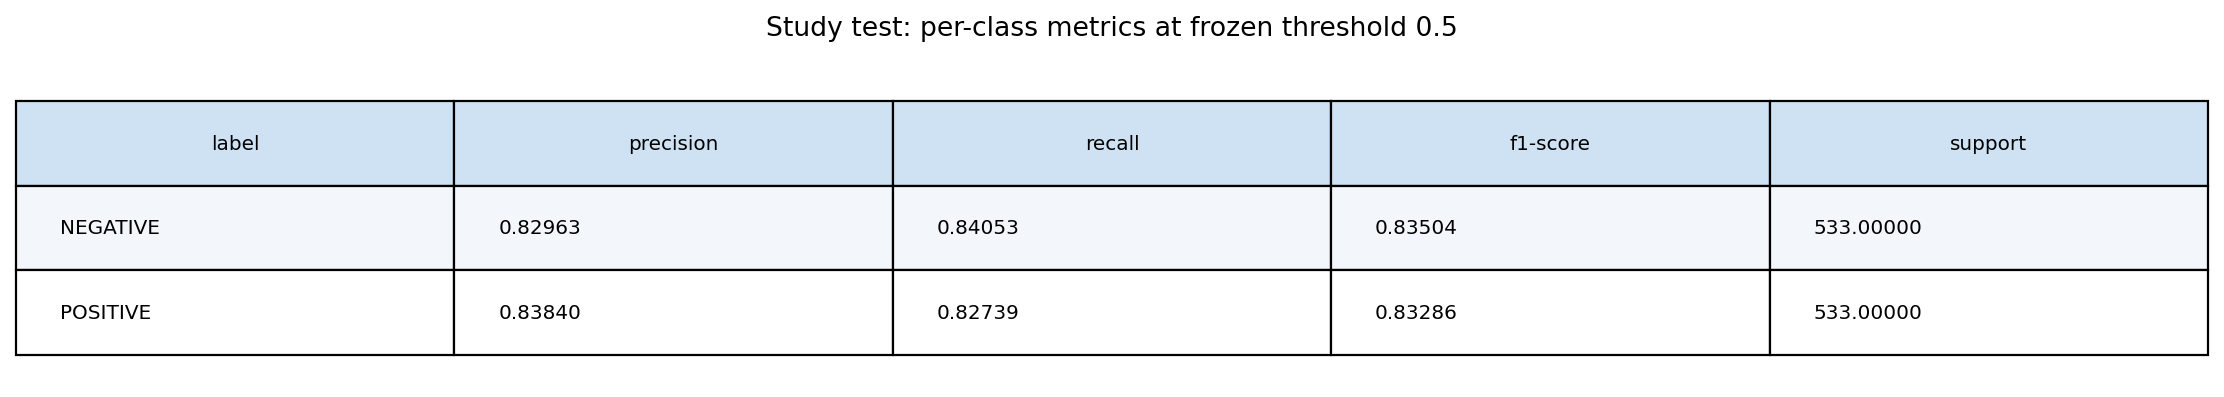

In [8]:
display(pd.DataFrame([read_json(study_run / "test_metrics.json")]))
display(pd.DataFrame([read_json(study_run / "test_threshold_metrics.json")]))
display(pd.DataFrame(study_tables["per_class"]))
show_study_image(study_run / "confusion_matrix.png", "**Test confusion matrix — argmax**")
show_study_image(study_run / "test_threshold/confusion_matrix.png", "**Test confusion matrix — frozen validation threshold 0.5**")
show_study_image(study_review / "per_class_metrics.png", "**Metric từng lớp, support=533 mỗi lớp**")

## P8 — Ranking, confidence và khoảng bất định

ROC-AUC **0,918416**, average precision **0,925989** cho biết khả năng xếp hạng; không có nghĩa accuracy đạt 91,84% hay confidence đã calibrated. Brier **0,150674**, top-label ECE **0,146071** và các ví dụ sai confidence >0,999 cho thấy confidence cần được thận trọng khi sử dụng.

Bootstrap phân tầng 2.000 lần cho model/policy cố định: Accuracy 95% percentile CI ≈ **[80,9568%; 85,6473%]**; Macro-F1 ≈ **[80,9568%; 85,6470%]**. Đây không phải khoảng bất định giữa các lần train, không bao gồm quá trình chọn hyperparameter và chỉ có một seed 42.

{'roc_auc': 0.918416411758287,
 'average_precision': 0.9259894498013682,
 'brier_score': 0.1506736755358776,
 'confidence_ece': 0.14607097334307081,
 'nll': 0.7980772048253766,
 'threshold': 0.5,
 'selection_split': 'validation',
 'bootstrap_95_percentile_ci': {'accuracy': [0.8095684803001876,
   0.8564727954971857],
  'macro_f1': [0.809568212168358, 0.8564696378079979]},
 'bootstrap_repeats': 2000,
 'ci_scope': 'fixed model, fixed threshold, stratified test sampling; excludes training-seed uncertainty'}

**ROC và Precision–Recall trên probabilities thật**

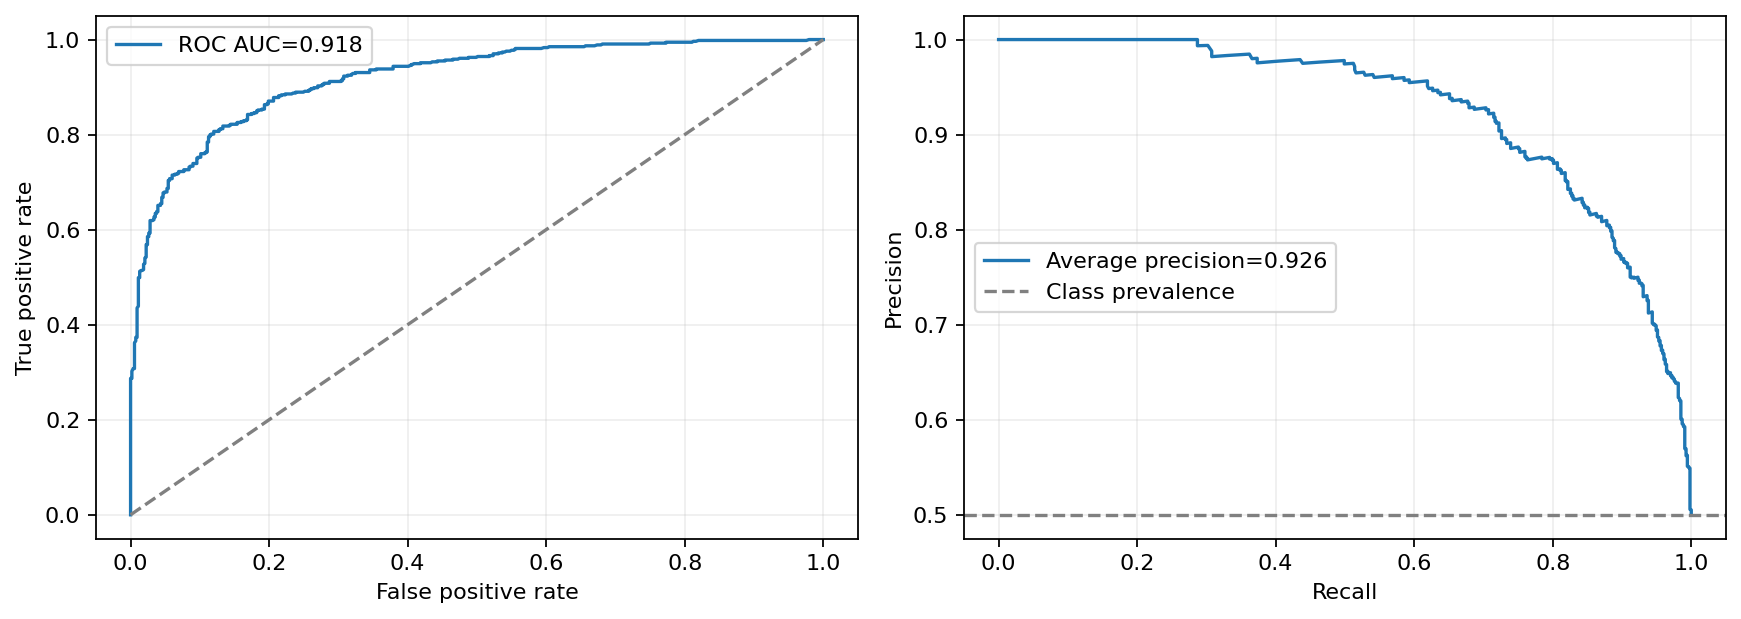

**Argmax confidence calibration và phân bố P(POSITIVE)**

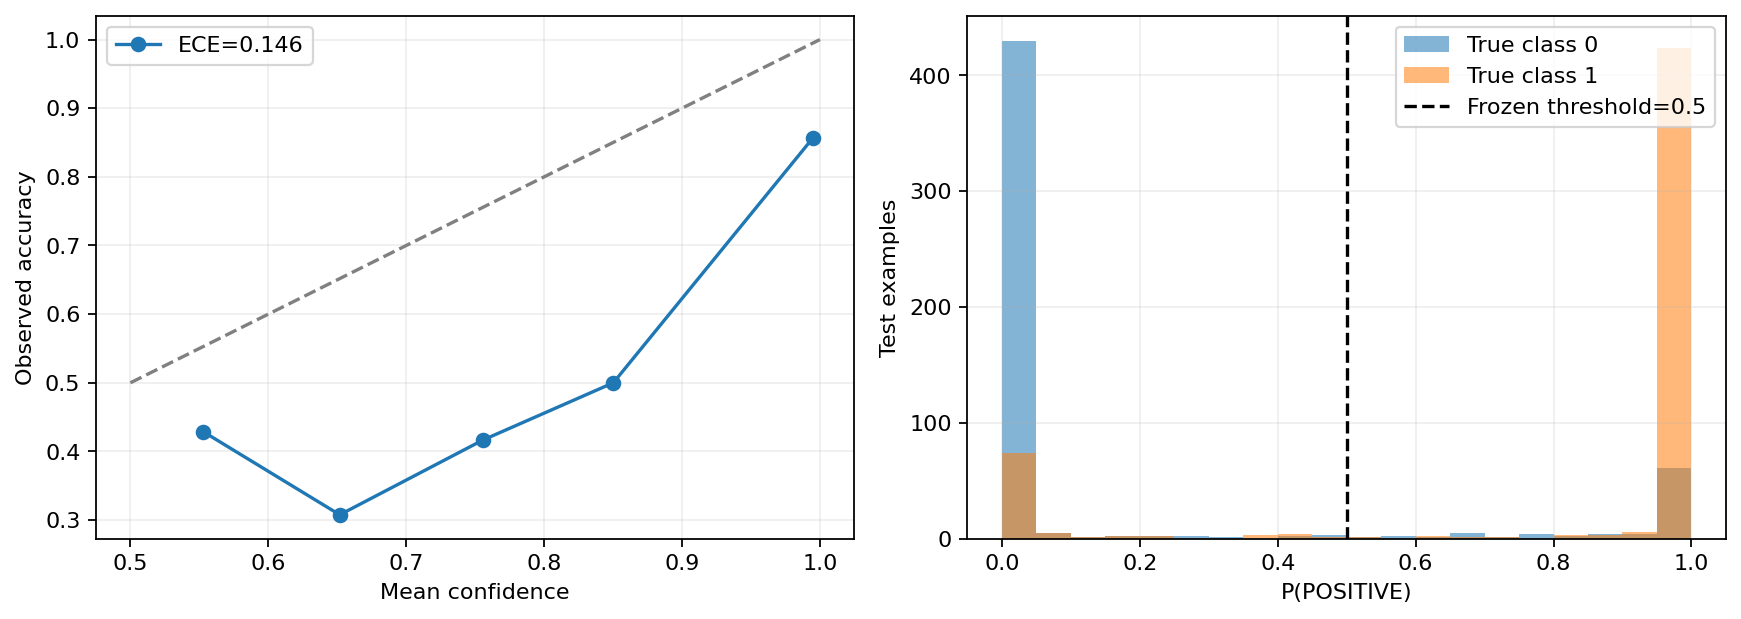

In [9]:
display(read_json(study_run / "probability_diagnostics.json"))
show_study_image(study_run / "roc_pr_curves.png", "**ROC và Precision–Recall trên probabilities thật**")
show_study_image(study_run / "calibration_confidence.png", "**Argmax confidence calibration và phân bố P(POSITIVE)**")

## P9 — So sánh với lịch sử 3 epoch: không ép kết luận cải thiện

Đã đối chiếu toàn bộ **index, text và nhãn** để bảo đảm cùng 1.066 test samples. Argmax lịch sử đúng 895; study đúng 889: giảm **6 mẫu / 0,5629 điểm phần trăm**. Study sửa 42 lỗi cũ nhưng sinh 48 lỗi mới; 847 mẫu cả hai đúng, 129 mẫu cả hai sai.

Paired stratified bootstrap CI 95% cho chênh accuracy (study − lịch sử) ≈ **[−2,3452; +1,2195] điểm phần trăm**, chứa 0. Không kết luận study vượt trội hoặc kém hơn có ý nghĩa thống kê từ chênh lệch này.

Đây không phải ablation chỉ thay epoch: còn khác LR được chọn, warmup/decay theo tổng ngân sách và criterion checkpoint. Test cũ từng được xem, nên cũng không gọi là blind test mới. Vẫn giữ winner LR=3e-5 theo validation; không đổi model vì đã thấy test của lịch sử cao hơn.

,same_test_cohort_verified,historical_correct,study_correct,both_correct,both_wrong,corrected_by_study,new_errors_in_study,accuracy_difference_study_minus_historical,paired_stratified_bootstrap_95_ci,bootstrap_repeats,bootstrap_seed,selection_performed,scope
0,True,895,889,847,129,42,48,-0.005629,"[-0.02345215759849906, 0.012195121951219513]",2000,42,False,descriptive comparison of two fixed prediction...


**Các nhóm đúng/sai trên cùng test cohort**

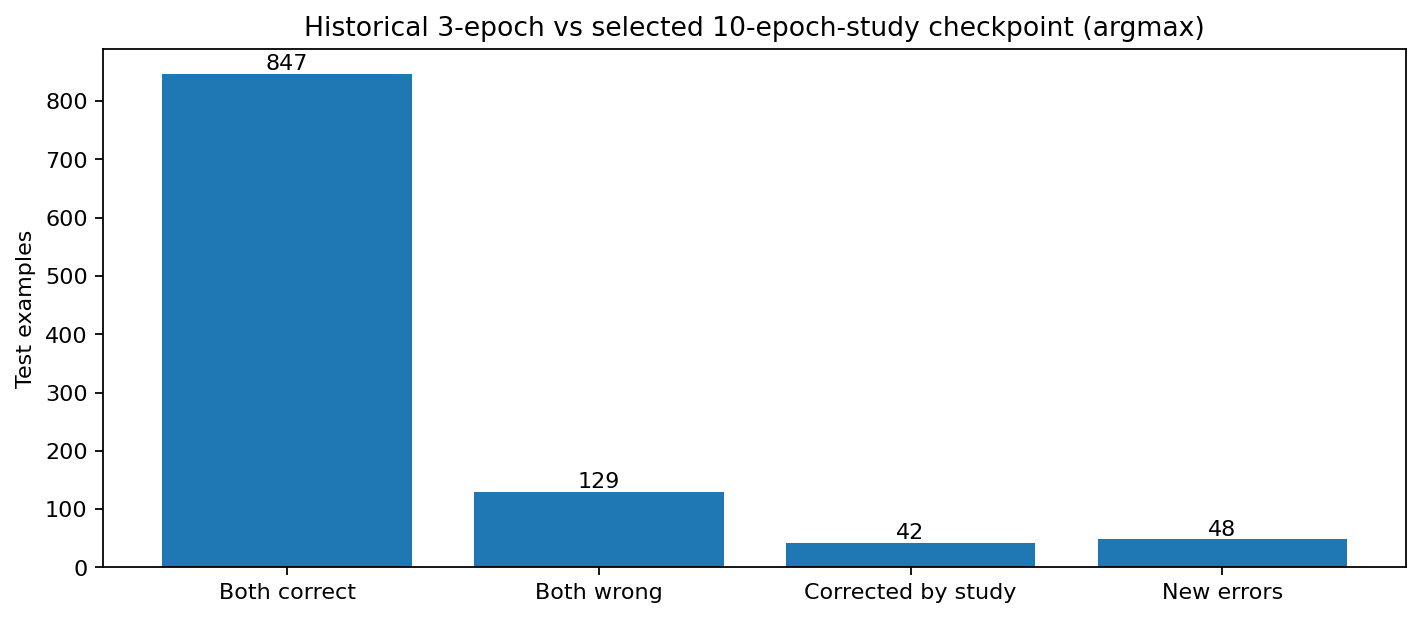

In [10]:
display(pd.DataFrame([study_tables["paired_comparison"]]))
show_study_image(study_review / "historical_paired_comparison.png", "**Các nhóm đúng/sai trên cùng test cohort**")

## P10 — Đọc lỗi và inference với policy đã chốt

- Câu “a very familiar tale…” bị dự đoán Positive dù nhãn Negative: phần “very familiar / told by countless filmmakers” có thể phê bình sự sáo mòn, còn nội dung sau mang từ vựng trung tính/nhân văn.
- Câu “entertains not so much… scrape the bottom…” bị Positive: cấu trúc tương phản và lời châm biếm có thể tạo tín hiệu xung đột.
- Câu “however canned… unexpectedly giddy viewing” bị Negative dù nhãn Positive: đánh giá cuối câu tích cực có thể bị lấn bởi sắc thái phủ định trước đó.
- Câu “almost puts the kibosh… otherwise a sumptuous work…” bị Negative: phê bình một đoạn không đồng nghĩa kết luận toàn phim tiêu cực.

Đó là cách đọc ngôn ngữ và giả thuyết giải thích lỗi, **không phải causal attribution của Transformer**. Mẫu confidence cao được chọn có chủ đích để kiểm tra lỗi tự tin, không đại diện ngẫu nhiên cho mọi lỗi. Không đổi threshold từ những câu test này.

**Ví dụ đúng/sai có confidence cao**

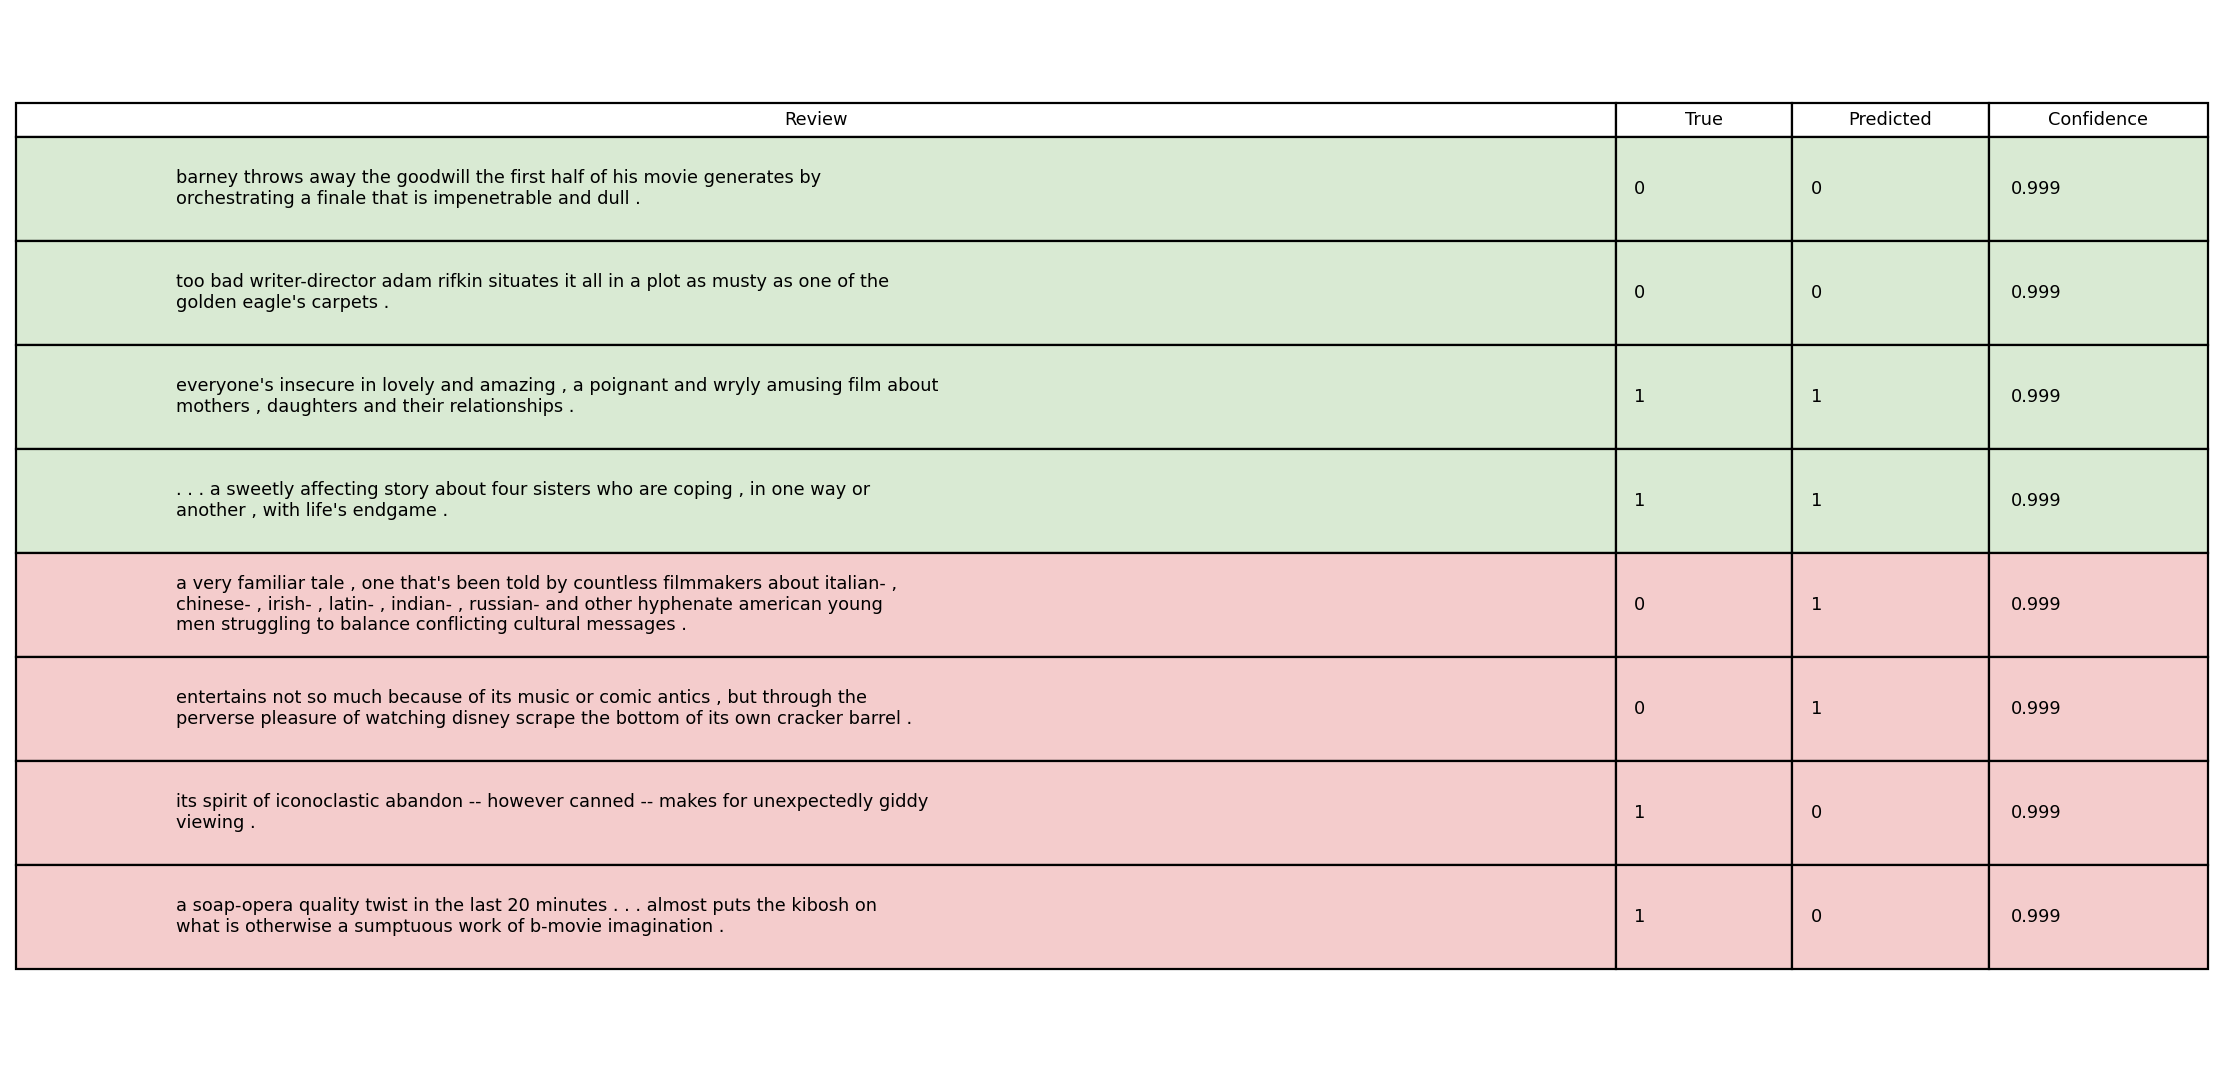

,index,text,true_label,predicted_label,confidence
0,1003,barney throws away the goodwill the first half...,0,0,0.999358
1,651,too bad writer-director adam rifkin situates i...,0,0,0.999356
2,94,"everyone's insecure in lovely and amazing , a ...",1,1,0.999256
3,510,. . . a sweetly affecting story about four sis...,1,1,0.999253
4,949,"a very familiar tale , one that's been told by...",0,1,0.999115
5,939,entertains not so much because of its music or...,0,1,0.999107
6,164,its spirit of iconoclastic abandon -- however ...,1,0,0.999331
7,216,a soap-opera quality twist in the last 20 minu...,1,0,0.999227


,index,true_label,predicted_label,positive_probability,decision_confidence,text
0,2,1,0,0.003046,0.996954,"it's like a "" big chill "" reunion of the baade..."
1,4,1,0,0.005820,0.994180,"red dragon "" never cuts corners ."
2,5,1,0,0.065366,0.934634,fresnadillo has something serious to say about...
3,7,1,0,0.002191,0.997809,weighty and ponderous but every bit as filling...
4,12,1,0,0.002901,0.997099,"mostly , [goldbacher] just lets her complicate..."
5,14,1,0,0.021410,0.978590,"at its worst , the movie is pretty diverting ;..."
6,21,1,0,0.399036,0.600964,making such a tragedy the backdrop to a love s...
7,28,1,0,0.002823,0.997177,devotees of star trek ii : the wrath of khan w...
8,36,1,0,0.003984,0.996016,"reminiscent of alfred hitchcock's thrillers , ..."
9,40,1,0,0.444685,0.555315,"you needn't be steeped in '50s sociology , pop..."


**Inference: checkpoint winner + frozen policy**

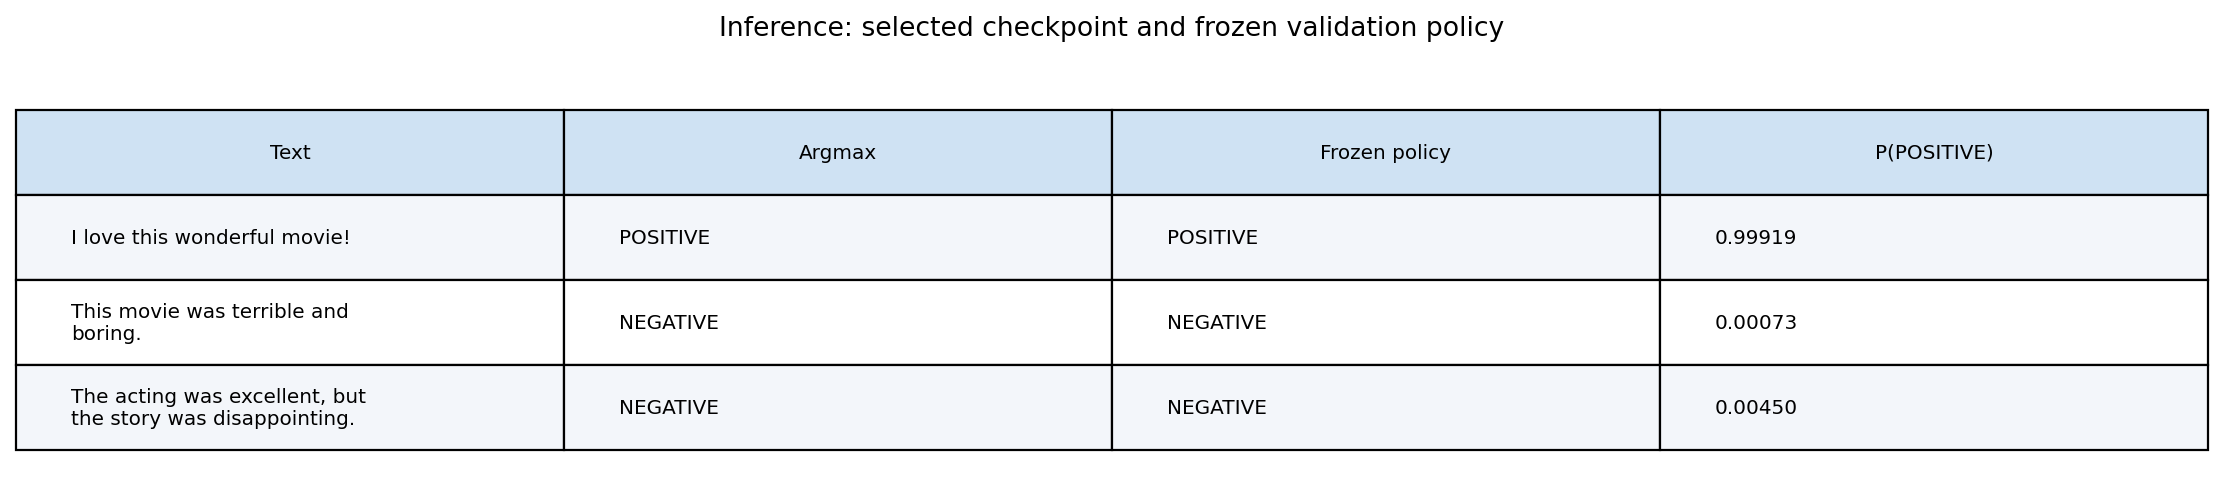

,text,score,probabilities,argmax_label,label,decision_threshold,selection_split
0,I love this wonderful movie!,0.999186,"[0.0008135565440170467, 0.9991864562034607]",POSITIVE,POSITIVE,0.5,validation
1,This movie was terrible and boring.,0.999271,"[0.9992706179618835, 0.0007293288363143802]",NEGATIVE,NEGATIVE,0.5,validation
2,"The acting was excellent, but the story was di...",0.995497,"[0.9954967498779297, 0.004503272473812103]",NEGATIVE,NEGATIVE,0.5,validation


In [11]:
show_study_image(study_run / "sample_predictions.png", "**Ví dụ đúng/sai có confidence cao**")
display(pd.DataFrame(read_json(study_run / "sample_predictions.json")))
display(pd.DataFrame(read_json(study_run / "threshold_errors.json")).head(12))
show_study_image(study_run / "inference_predictions.png", "**Inference: checkpoint winner + frozen policy**")
display(pd.DataFrame(read_json(study_run / "inference_predictions.json")))

## P11 — Artifact, nghiệm thu và giới hạn còn lại

Review ZIP giữ **đủ raw logs** và original manifests của cả ba candidate, study, Exercise 1, Kaggle audit và preflight. Cả ba candidate có exact weight verification trên Kaggle; final study tải lại winner trước test. ZIP review cố ý bỏ checkpoints, vì vậy môi trường review chỉ kiểm toán predictions/policy/hash, không thực thi lại weights.

Các hình/bảng đã nằm trong `outputs/runs/`; `outputs/published/` xuất bản sao theo `config/report.json`, primary result là study mới. Các role lịch sử vẫn giữ riêng để đối chiếu. Artifact notebook đã thực thi được lưu trong run `notebook_render`; không sửa raw science records để khớp bài viết.

**Không cần train lại để hoàn thiện báo cáo này.** Giữ checkpoint ZIP để inference/reload sau này. Nếu nghiên cứu tiếp, cần thiết kế nhiều seed hoặc calibration/đánh giá ngoài trước khi chạy; đó là công việc bổ sung, không được suy ra đã hoàn thành từ study hiện tại.

In [12]:
display({"study_run":study_run.name,"audit":study_audit["status"],
         "candidates":study_audit["candidate_count"],"epochs_each":study_audit["epochs_per_candidate"],
         "weights_loaded_locally":False,"new_training_executed":False,
         "report_primary":read_json(LAB / "config/report.json")["primary_result"]})
print("Nguồn bảng:", study_review / "tables.json")
print("Báo cáo gốc tự xuất:", study_run / "study_report.md")
print("Report artifacts:", LAB / "outputs/published/index.md")

{'study_run': '20261026T184219Z_study_94f2ba7b',
 'audit': 'passed',
 'candidates': 3,
 'epochs_each': 10,
 'weights_loaded_locally': False,
 'new_training_executed': False,
 'report_primary': 'frozen_trial'}

Nguồn bảng: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T191751Z_study_review_d66d4edb/tables.json
Báo cáo gốc tự xuất: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T184219Z_study_94f2ba7b/study_report.md
Report artifacts: /workspace/Lab-DL-completion/labs/lab03/outputs/published/index.md
